# 19 — Modelado: qué modelos se usan, por qué se eligieron y qué se ha probado

**Autor:** Jason Sepúlveda S.
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [`03-jss-eda.ipynb`](03-jss-eda.ipynb) ·
[`05-jss-seleccion-juez.ipynb`](05-jss-seleccion-juez.ipynb) ·
[`06-jss-ajuste-c1.ipynb`](06-jss-ajuste-c1.ipynb) ·
[`07-jss-runner-experimento-b.ipynb`](07-jss-runner-experimento-b.ipynb) ·
[`10-jss-potencia-criterio-d16.ipynb`](10-jss-potencia-criterio-d16.ipynb) ·
[`12-jss-extraccion-openkos-es2015.ipynb`](12-jss-extraccion-openkos-es2015.ipynb) ·
[`14-jss-alineacion-experimento-a.ipynb`](14-jss-alineacion-experimento-a.ipynb) ·
[`15-jss-screen-de-modelos-openkos.ipynb`](15-jss-screen-de-modelos-openkos.ipynb) ·
[`16-jss-c2-fuentes-e1.ipynb`](16-jss-c2-fuentes-e1.ipynb) ·
[`17-jss-tau-referencia-en.ipynb`](17-jss-tau-referencia-en.ipynb) ·
[ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md) ·
[ADR 0006](../docs/decisions/0006-adr-c1-rag-separado-con-respuesta-de-openkos.md) ·
[ADR 0007](../docs/decisions/0007-adr-ajuste-c1-y-presupuesto-de-contexto.md) ·
[ADR 0010](../docs/decisions/0010-adr-decisiones-del-analisis-del-experimento-b.md) ·
[ADR 0011](../docs/decisions/0011-adr-alineacion-rol-e-intervalos-del-experimento-a.md) ·
[ADR 0012](../docs/decisions/0012-adr-umbral-tau-del-experimento-a.md) ·
[documento 09](../docs/avances/09-jss-modelos-y-justificacion.md) ·
issues #94 · #143 · #145 · #146

---

> **Estado: descriptivo y de desarrollo; no contiene resultados de la tesis.** Este notebook
> presenta la etapa de modelado: qué se compara, con qué modelos, cómo se eligieron y qué se
> probó hasta ahora. Toda cifra de desempeño sale de series de **desarrollo** (ES2015 y, para
> la extracción, también TS3009; [ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md)).
> Las series de evaluación aparecen **solo como conteos estructurales**; su contenido no se
> leyó. **No se corrió ningún modelo**: el notebook lee resultados guardados en `reports/`
> (por eso se ejecuta de punta a punta sin Ollama; para las cifras estructurales necesita el
> corpus AMI y las transcripciones congeladas). Con 21 preguntas, una corrida por condición y
> una sola serie, las cifras de la sección 7 indican una dirección y no permiten concluir.

## Un caso para entrar en materia

La misma pregunta, formulada a tres sistemas sobre la serie de desarrollo ES2015 (el equipo
que diseña un control remoto). **C0** responde sin ningún texto de apoyo, solo con lo que el
modelo ya sabe. **C1** busca fragmentos de la transcripción y responde con ellos. **C2**
responde desde una base de decisiones que otro proceso construyó antes a partir de la
transcripción. La columna «¿correcta?» es el veredicto del modelo juez frente a la respuesta
de referencia escrita por una persona.

In [1]:
import json
from dataclasses import replace

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from afg import eda
from afg.conditions.c1_ablation import ABLATION_PATH, load_ablation_results
from afg.conditions.c1_prompt_budget import budget_chars
from afg.conditions.c1_tuning import RESULTS_PATH as C1_TUNING_PATH
from afg.conditions.c1_tuning import (
    load_tuning_results,
    questions_with_any_delivered_hit,
    select_winner,
)
from afg.eda.figures import (
    plot_grouped_bars,
    plot_hbars,
    plot_labeled_scatter,
    save_figure,
    video_style,
)
from afg.eda.modeling import context_constraints, partition_volumes
from afg.eda.tables import format_thousands as es
from afg.eda.tables import turn_length_distribution
from afg.evaluation.judge_calibration_results import RESULTS_PATH as JUDGE_RESULTS_PATH
from afg.evaluation.judge_calibration_results import load_calibration_results
from afg.evaluation.judge_calibration_worksheet import WORKSHEET_PATH
from afg.evaluation.reference import load_series_reference, reference_figures
from afg.experiments.c2_base_evidence import count_stages, read_worksheet_rows, stage_shares
from afg.experiments.c2_context import context_rows, error_evidence
from afg.experiments.cost_table import (
    answer_and_judge_costs,
    compare_to_baseline,
    cost_frame,
    extraction_manifest_cost,
    judge_calibration_costs,
    screen_by_model,
    screen_costs,
    screen_quality,
    screen_rule,
    screen_winner,
    tau_judge_cost,
)
from afg.experiments.extraction_runs import (
    decisions_per_meeting,
    load_extraction_runs,
    pairwise_overlap,
    provenance_table,
    reproducibility_check,
)
from afg.experiments.model_screen import (
    FAILURE_FLOOR,
    MARGIN_FLOOR,
    SELECTION_TAU,
    VOLUME_FACTOR,
    language_counts,
    load_pass_runs,
)
from afg.experiments.power import PowerScenario, power_settings_from_config, simulate_scenario
from afg.experiments.provenance import manifest_provenance_table
from afg.experiments.questions import load_experiment_questions
from afg.experiments.runner import MANIFEST_FILE, RECORDS_FILE, load_records
from afg.experiments.summary import (
    abstention_causes,
    failure_split,
    inline_marker_rows,
    stratum_summary,
)
from afg.experiments.tau_calibration import (
    JudgmentStore,
    bin_table,
    load_stored_judgments,
    tau_judge,
)
from afg.extraction.openkos.event_dates import date_availability_summary, meeting_date_table
from afg.shared.config import load_corpus_config, load_experiments_config
from afg.shared.paths import (
    AMI_DIR,
    EXPERIMENT_A_DIR,
    EXPERIMENT_B_DIR,
    GOLD_DECISIONS_DIR,
    PROJECT_ROOT,
    QUESTIONS_DIR,
    TRANSCRIPTS_DIR,
)

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 30)

FIGURES_DIR = PROJECT_ROOT / "docs" / "entregables" / "figuras"
EXPORTED = []  # paths of the PNGs exported for the video, in order

# Guard: the corpus, the frozen transcripts and the stored runs are needed.
if not AMI_DIR.exists() or not any(AMI_DIR.glob("abstractive/*.xml")):
    raise SystemExit(f"Falta el corpus AMI en {AMI_DIR}. Ejecuta: uv run afg corpus download")
if not TRANSCRIPTS_DIR.exists() or not any(TRANSCRIPTS_DIR.glob("*.jsonl")):
    raise SystemExit(f"Faltan las transcripciones congeladas en {TRANSCRIPTS_DIR}.")

CFG = load_experiments_config()
SB = CFG["shared_budget"]
CORPUS = load_corpus_config()["oe1"]

B_RUNS = {
    "C0": EXPERIMENT_B_DIR / "diagnostico-sin-contexto-es2015",
    "C1": EXPERIMENT_B_DIR / "humo-c1-es2015",
    "C2": EXPERIMENT_B_DIR / "humo-c2-es2015-conceptos",
}
for needed in (WORKSHEET_PATH, *(run / RECORDS_FILE for run in B_RUNS.values())):
    if not needed.exists():
        raise SystemExit(f"No se encontro {needed}. Ver notebooks/README.md (Reproducibilidad).")

QUESTIONS = {q.id: q for q in load_experiment_questions(WORKSHEET_PATH)}
RECORDS = {
    name: load_records(path / RECORDS_FILE, latest_only=True) for name, path in B_RUNS.items()
}


def pct(fraction, decimals=1):
    """Presentation only: 0.5694 -> '56,9 %'."""
    return f"{es(fraction * 100, decimals)} %"


def md(text):
    display(Markdown(text))


EXAMPLE = "ES2015.q002"
case = pd.DataFrame(
    [
        {
            "sistema": name,
            "respuesta": next(r for r in records if r["question_id"] == EXAMPLE and r["run"] == 0)[
                "answer"
            ]["text"]
            .split("USED:")[0]
            .strip(),
            "¿correcta?": next(r for r in records if r["question_id"] == EXAMPLE and r["run"] == 0)[
                "verdict"
            ]["correct"],
        }
        for name, records in RECORDS.items()
    ]
).set_index("sistema")
print("Pregunta  :", QUESTIONS[EXAMPLE].text)
print("Referencia:", QUESTIONS[EXAMPLE].reference_answer)
case

Pregunta  : What selling price was set for the remote control?
Referencia: Twenty-five Euros.


,respuesta,¿correcta?
sistema,,
C0,I don't have any information about a specific remote control or its selling price. Please provide more context or de...,False
C1,The selling price that was set for the remote control is twenty five Euros.,True
C2,"Matching concepts were found in the compiled bundle, but none of them answers this question.",False


**Lectura.** Con la misma pregunta, C0 admite que no sabe, C1 encuentra el pasaje y acierta,
y C2 (en esta corrida de desarrollo) se abstiene aunque el precio sí está en la reunión. Eso
es lo que el proyecto quiere medir con muchas preguntas: **cuánto cambia la respuesta según la
forma de organizar la información**. Este notebook explica con qué piezas se hace esa
medición, por qué se eligieron y qué se probó hasta ahora; no es todavía la medición.

---

# Cómo leer este notebook

## Qué pide el curso y por qué aquí se traduce

La semana 4 del curso pide mostrar el **primer acercamiento al modelado**: qué modelos se
exploran, por qué se eligieron en relación con el problema, y qué avance inicial hay
(intentos, parámetros, librerías y dificultades), todo de forma coherente y reflexiva. La
clase sobre «¿cómo elegir modelos?» agrega las prácticas esperadas: separar un conjunto de
prueba y usarlo una sola vez, definir la métrica de éxito desde los objetivos, considerar el
costo de los errores y las restricciones del análisis exploratorio, informar el reparto en
porcentajes **y** en volúmenes, validar con validación cruzada o temporal, tratar el
preprocesamiento y el modelo como un solo *pipeline*, declarar cómo se buscan los
hiperparámetros, **comparar siempre contra una línea base simple**, justificar las decisiones
y reconocer las limitaciones. La diapositiva 24 («Sugerencias para el informe») pide cuatro cosas: el
*baseline* con el que se comparan (describir el *pipeline* simple usado como línea de base y su
rendimiento); la elección del *pipeline* final (justificar por qué se seleccionaron los
*pipelines* candidatos y la arquitectura final, conectando la decisión con el tipo de problema y
los hallazgos del EDA); el proceso de optimización (detallar las herramientas y librerías
utilizadas y cómo se optimizaron los hiperparámetros del *pipeline* ganador); y el análisis
crítico y las limitaciones (comparar el rendimiento del *pipeline* final contra el *baseline* y
discutir las limitaciones del *pipeline* elegido).

Este proyecto **no entrena ningún modelo**. Los modelos de lenguaje (LLM) que usa ya vienen
entrenados y se ejecutan en el propio computador con Ollama, un servidor local de modelos.
Lo que se evalúa es si una forma de organizar la información responde mejor que otra. Por
eso cada práctica del curso tiene un **equivalente propio**, que esta tabla fija y que
ordena todo el notebook.

## Lo que pide el curso → su equivalente en esta tesis → dónde se cubre

| Lo que pide el curso | Su equivalente en esta tesis | Sección |
|---|---|---|
| **El modelo** (algoritmo que se entrena) | El ***pipeline* completo de cada condición**: C1 (buscar fragmentos y responder), C2 (base de decisiones construida por la máquina con OpenKOS) y C3 (la misma base construida por personas). Cada uno junta recuperación, modelo de *embeddings*, modelo generador y *prompt*. Nada se entrena | 4 y 5 |
| **Conjunto de prueba** separado y usado una vez | Las **series de evaluación**, que no se tocan hasta congelar todo ([ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md)). Lo ajustable se ajusta solo en las series de desarrollo | 3 |
| **Fuga de datos** (*leakage*) | Horizonte cronológico (las reuniones se procesan de la a a la d, con fechas ordenadas, [ADR 0008](../docs/decisions/0008-adr-fechas-de-reunion-para-openkos.md)), regla «congelar antes de evaluar» y una **fuga declarada** (issue #145: dos umbrales de troceo de OpenKOS se midieron con una serie de evaluación) | 3 y 10 |
| **Validación cruzada o temporal** | Como no hay entrenamiento no hay *folds*. La variabilidad se mide con **3 corridas con semilla**, **bootstrap por reuniones** ([ADR 0011](../docs/decisions/0011-adr-alineacion-rol-e-intervalos-del-experimento-a.md)) y un tamizaje de modelos que exige ganar en **las dos series de desarrollo** (ES2015 y TS3009), el equivalente a la consistencia entre *folds* | 6 y 8 |
| **Hiperparámetros** | Modelo elegido, `temperature`, `top_p`, ventana de contexto, tamaño de fragmento, número de fragmentos recuperados (K) y el umbral de alineación τ. Los ***prompts* quedan fijos a propósito** (copiados de OpenKOS, [ADR 0006](../docs/decisions/0006-adr-c1-rag-separado-con-respuesta-de-openkos.md)) para que la instrucción no explique la diferencia | 6 |
| **Método de búsqueda** de hiperparámetros | ***Grid search*** (C1, 32 configuraciones), **tamizaje prerregistrado** con reglas de veto (modelo de extracción), **umbrales prerregistrados** (modelo juez) y **ablación** (canales de recuperación) | 6 |
| **Línea base** simple | **C1** (RAG documental, ajustado con honestidad) y el diagnóstico sin contexto **C0**, que mide qué aporta recuperar texto | 7 |
| **Métrica de éxito** desde los objetivos | Por objetivo (OE2 a OE4) y el **criterio D16/D17**: diferencia pareada de la corrección de respuesta C2 − C1 en las preguntas de evolución (E3) | 1 |
| **Costo de los errores** | Qué cuesta responder mal, abstenerse, extraer una decisión falsa o perder una | 1 |
| **Restricciones del EDA** | Largo de las transcripciones frente a la ventana, decisiones raras, series temporales, idioma | 2 |
| **Reparto en % y en volúmenes** | Tabla con series, reuniones, frases de decisión y pares candidatos por partición, calculada con código | 3 |
| **Evaluación final una sola vez** | **Congelar y luego correr**: todo lo ajustado se registra antes de abrir las series de evaluación | 10 |
| **Limitaciones** | Lista explícita | 11 |

## De este notebook salen

El notebook es la fuente única del **avance escrito** (actualización del documento 09) y del
**guion del video** (máximo 10 minutos, tres voces). Esta tabla dice qué sección alimenta
cada bloque del video y cada uno de los cuatro puntos de la diapositiva 24.

| Bloque del video (propuesta) | Qué cubre | Secciones |
|---|---|---|
| **Bloque 1** (≈ 3 min) | El problema, qué significa «funcionar bien», restricciones de los datos y cómo se reparten | 1, 2, 3 |
| **Bloque 2** (≈ 4 min) | Los *pipelines*, los modelos por rol y cómo se buscaron los parámetros | 4, 5, 6 |
| **Bloque 3** (≈ 3 min) | Línea base y primeros resultados, dificultades, qué falta y limitaciones | 7, 8, 9, 10, 11 |

| Punto de la diapositiva 24 | Secciones |
|---|---|
| 1. Baseline con el que se comparan: el *pipeline* simple y su rendimiento | 7 |
| 2. La elección del *pipeline* final: por qué los candidatos y la arquitectura, ligados al problema y al EDA | 2, 4, 5 |
| 3. El proceso de optimización: herramientas, librerías e hiperparámetros del *pipeline* ganador | 6, 8 |
| 4. Análisis crítico (final frente al *baseline*) y limitaciones | 7, 9, 11 |

La sección 12 reúne los mensajes clave, cada uno con su cifra y su sección, listos para
llevar al avance y al guion.

## Glosario

Los términos técnicos establecidos se mantienen tal cual; cada uno se explica aquí.

| Término | Qué significa en este notebook |
|---|---|
| **LLM** (modelo de lenguaje) | Programa entrenado con enormes cantidades de texto que redacta respuestas. Aquí solo se usan modelos ya entrenados, ejecutados en local con **Ollama** |
| **RAG** | Generación aumentada por recuperación: antes de responder se buscan los pasajes más parecidos a la pregunta y el modelo responde con ellos |
| **OpenKOS** | Motor de código abierto que construye una base de decisiones a partir de transcripciones y responde consultas sobre ella. Es el **instrumento** de C2 y C3, no un aporte de la tesis ([ADR 0003](../docs/decisions/0003-adr-openkos-as-instrument.md)) |
| **Base compilada** | Los objetos que OpenKOS guarda tras leer las reuniones: decisiones, resúmenes de temas (*concepts*), eventos y la fuente en bruto (*sources*) |
| **C0, C1, C2, C3** | C0: diagnóstico sin contexto (no es una condición de la tesis). C1: RAG documental, la línea base. C2: base construida automáticamente. C3: la misma base construida desde la anotación humana |
| **E1 a E4** | Estratos de preguntas: E1 hecho puntual, E2 estado vigente, E3 evolución de una decisión (el que prueba la tesis), E4 sin respuesta en el material |
| **OE1 a OE4** | Objetivos: OE1 referencia humana, OE2 calidad de la extracción (Experimento A), OE3 utilidad funcional (Experimento B), OE4 atribución del error |
| ***Embedding*** | Representación numérica de un texto; sirve para medir qué tan parecidos son dos textos (similitud coseno) |
| **BM25 / RRF** | BM25 recupera por palabras compartidas; RRF (*reciprocal rank fusion*) combina dos listas ordenadas premiando lo que aparece bien ubicado en ambas |
| **Fragmento** (*chunk*) | Trozo de transcripción hecho de turnos de habla completos, con un tope de caracteres |
| **Ventana de contexto** | Cantidad máxima de texto que el modelo lee de una vez |
| `temperature`, `top_p`, **semilla** | Controles del azar al redactar. Con semilla y temperatura bajas el modelo responde casi siempre igual |
| **Juez** (LLM-as-a-judge) | Segundo modelo que califica si una respuesta es correcta. Es la regla de medir, no un modelo bajo prueba |
| **Kappa de Cohen** | Acuerdo entre dos calificadores descontado el azar; 1 es acuerdo perfecto |
| **τ** | Umbral de similitud con que se decide si una decisión extraída es «la misma» que una de la referencia |
| **Precision, recall, F1** | Qué parte de lo extraído es correcto; qué parte de lo que había se encontró; su media armónica |
| **Bootstrap** | Repetir el cálculo sobre muestras al azar del mismo conjunto para saber cuánto podría variar el resultado |
| **Prerregistro** | Regla de decisión escrita y fechada antes de ver resultados, para no ajustarla después |
| **Desarrollo / evaluación** | Series usadas para tomar decisiones frente a series usadas para reportar resultados ([ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md)) |
| **Ablación** | Quitar una pieza (aquí, un canal de recuperación) para ver cuánto aportaba |
| **Línea base** (*baseline*) | Sistema simple contra el cual se mide la propuesta |

---

# 1. El problema y qué significa «funcionar bien»

**Qué se hace y por qué.** Antes de elegir modelos hay que decir qué se quiere que hagan y
cómo se sabrá que lo hicieron bien. La pregunta del proyecto es si **una base estructurada de
decisiones, construida automáticamente desde transcripciones de reuniones, responde mejor que
buscar en las transcripciones**, y cuánto se pierde cuando la construye una máquina que se
equivoca. Las respuestas del problema deciden qué piezas se necesitan: un sistema que busca
texto (C1), un sistema que consulta una base (C2), la misma base hecha por personas (C3) para
separar el valor de la idea del costo de los errores de la máquina, y un juez que califique
las respuestas.

## 1.1 Objetivos, métrica y regla de lectura

In [2]:
EVAL, QB, JC = CFG["evaluation"], CFG["question_bank"], CFG["judge"]["calibration"]
TAU_GRID = CFG["alignment"]["tau_grid"]
OBJECTIVES = pd.DataFrame(
    [
        {
            "objetivo": "OE1 — referencia humana",
            "pregunta": "¿Se puede construir una referencia de decisiones y relaciones confiable?",
            "métrica": "Kappa de Cohen en tres ejes (existencia, tipo, dirección)",
            "regla de lectura": "Sin umbral por diseño: un kappa bajo se informa como hallazgo",
        },
        {
            "objetivo": "OE2 — extracción (Experimento A)",
            "pregunta": "¿Qué tan bien reencuentra la máquina las decisiones de la referencia?",
            "métrica": (
                f"Precision, recall y F1 como curva sobre τ ({es(min(TAU_GRID), 2)} a "
                f"{es(max(TAU_GRID), 2)}, {len(TAU_GRID)} valores)"
            ),
            "regla de lectura": "Sin criterio de éxito; τ principal 0,70 con 0,75 y 0,80 de "
            "sensibilidad (ADR 0012)",
        },
        {
            "objetivo": "OE3 — utilidad (Experimento B)",
            "pregunta": "¿Responde mejor C2 que C1, sobre todo cuando la decisión cambió?",
            "métrica": (
                "Corrección de la respuesta, calificada por el juez; principal en E3 "
                f"(≥ {QB['min_questions']} preguntas por estrato)"
            ),
            "regla de lectura": (
                "Criterio D16 enmendado por D17: IC de la diferencia pareada C2 - C1 en E3 "
                f"({pct(EVAL['bootstrap_confidence_level'], 0)}, "
                f"{es(EVAL['bootstrap_resamples'])} remuestreos) por encima de 0"
            ),
        },
        {
            "objetivo": "OE4 — atribución del error",
            "pregunta": "Cuando C2 falla, ¿dónde nació el error?",
            "métrica": "Proporción de errores por etapa: extracción, recuperación o síntesis",
            "regla de lectura": "Descriptivo; la cifra principal es la parte atribuible a "
            "extracción",
        },
    ]
).set_index("objetivo")
OBJECTIVES

,pregunta,métrica,regla de lectura
objetivo,,,
OE1 — referencia humana,¿Se puede construir una referencia de decisiones y relaciones confiable?,"Kappa de Cohen en tres ejes (existencia, tipo, dirección)",Sin umbral por diseño: un kappa bajo se informa como hallazgo
OE2 — extracción (Experimento A),¿Qué tan bien reencuentra la máquina las decisiones de la referencia?,"Precision, recall y F1 como curva sobre τ (0,50 a 0,90, 9 valores)","Sin criterio de éxito; τ principal 0,70 con 0,75 y 0,80 de sensibilidad (ADR 0012)"
OE3 — utilidad (Experimento B),"¿Responde mejor C2 que C1, sobre todo cuando la decisión cambió?","Corrección de la respuesta, calificada por el juez; principal en E3 (≥ 25 preguntas por estrato)","Criterio D16 enmendado por D17: IC de la diferencia pareada C2 - C1 en E3 (95 %, 10.000 remuestreos) por encima de 0"
OE4 — atribución del error,"Cuando C2 falla, ¿dónde nació el error?","Proporción de errores por etapa: extracción, recuperación o síntesis",Descriptivo; la cifra principal es la parte atribuible a extracción


**Lectura.** Cada objetivo tiene su propia métrica, y solo una comparación decide si el
experimento «tuvo éxito»: la **corrección de la respuesta en las preguntas de evolución (E3),
de C2 frente a C1**. Para cada pregunta se calcula cuánto mejor o peor le fue a C2 que a C1,
se arma un intervalo bootstrap de la diferencia promedio, y hay tres desenlaces: *respaldada*
(el intervalo queda por encima de 0), *no concluyente* (incluye el 0; nunca se reporta como
éxito) y *contraria* (por debajo de 0). Todo lo demás (precision, citación, costo) es
descriptivo. Escribirlo antes de ejecutar nada evita reinterpretar los resultados después
(documento 08, §6).

## 1.2 Cuánta potencia tiene ese criterio

Con pocas preguntas en E3 el criterio podría no detectar una mejora real. Se simularon
experimentos sintéticos (no se ejecuta ningún modelo) con una exactitud base de C1 de 0,5 y
una dispersión de dificultad de 1, para ver con qué frecuencia el criterio pareado declara
«respaldada» y cuántas veces lo hace el criterio alternativo de no solapamiento de
intervalos ([ADR 0010](../docs/decisions/0010-adr-decisiones-del-analisis-del-experimento-b.md)).

In [3]:
POWER_SETTINGS = power_settings_from_config()
POWER_ROWS = []
for n_questions in (QB["min_questions"], 40):
    for difference in (0.0, 0.15, 0.20):
        r = simulate_scenario(
            PowerScenario(n_questions, SB["runs_per_config"], 0.5, difference, 1.0),
            POWER_SETTINGS,
        )
        POWER_ROWS.append(
            {
                "preguntas en E3": n_questions,
                "mejora verdadera de C2": f"+{es(difference, 2)}",
                "criterio pareado (vigente)": pct(r.power_paired),
                "no solapamiento (robustez)": pct(r.power_nonoverlap),
            }
        )
POWER = pd.DataFrame(POWER_ROWS).set_index(["preguntas en E3", "mejora verdadera de C2"])
print(
    f"{es(POWER_SETTINGS.n_simulations)} experimentos simulados por escenario; "
    f"{SB['runs_per_config']} corridas por pregunta."
)
POWER

1.000 experimentos simulados por escenario; 3 corridas por pregunta.


criterio pareado (vigente) no solapamiento (robustez)
preguntas en E3 mejora verdadera de C2                                                      
25              +0,00                                       3,3 %                      0,0 %
                +0,15                                      57,5 %                     10,4 %
                +0,20                                      79,5 %                     27,8 %
40              +0,00                                       2,8 %                      0,0 %
                +0,15                                      75,7 %                     17,4 %
                +0,20                                      93,8 %                     49,1 %

In [4]:
p25 = POWER.loc[(QB["min_questions"], "+0,15")]
p25_zero = POWER.loc[(QB["min_questions"], "+0,00")]
md(
    f"**Lectura.** Con {QB['min_questions']} preguntas en E3 y una mejora verdadera de +0,15, el "
    "criterio "
    f"pareado declara «respaldada» en {p25['criterio pareado (vigente)']} de los experimentos "
    "simulados, "
    f"frente a {p25['no solapamiento (robustez)']} del criterio de no solapamiento; cuando no hay "
    "mejora "
    f"real declara «respaldada» en {p25_zero['criterio pareado (vigente)']} (los falsos "
    "positivos). Por eso "
    "se eligió la diferencia pareada: tiene más potencia sin inflar los falsos positivos. "
    "Es una simulación: dice cuánta potencia tiene el criterio, no cuánto mejorará C2."
)

**Lectura.** Con 25 preguntas en E3 y una mejora verdadera de +0,15, el criterio pareado declara «respaldada» en 57,5 % de los experimentos simulados, frente a 10,4 % del criterio de no solapamiento; cuando no hay mejora real declara «respaldada» en 3,3 % (los falsos positivos). Por eso se eligió la diferencia pareada: tiene más potencia sin inflar los falsos positivos. Es una simulación: dice cuánta potencia tiene el criterio, no cuánto mejorará C2.

## 1.3 El costo de los errores

No todos los errores cuestan lo mismo, y el diseño lo tiene en cuenta en cómo mide y cómo
informa. La tabla separa lo que **el diseño ya decide** (cómo se cuenta cada error) de lo
que se informa **aparte** para que no quede escondido en un promedio.

| Error | Cómo se cuenta en la medición | Por qué importa | Dónde se ve |
|---|---|---|---|
| **Responder mal** una pregunta que sí tiene respuesta (E1 a E3) | Respuesta incorrecta | Es el error «confiado»: el usuario cree una respuesta falsa. La hipótesis H4 espera más de esto en C1 que en C2 | Sección 7, división de los fallos |
| **Abstenerse** (decir «no hay información») en una pregunta que sí tiene respuesta | También incorrecta, pero se informa **aparte** | No ayuda, pero tampoco engaña: distinguir «no sabe» de «se equivoca» cambia qué conviene mejorar | Sección 7 |
| **Abstenerse** en una pregunta sin respuesta (E4) | **Correcta**: es la única situación en que abstenerse es la respuesta buena | Mide si el sistema reconoce sus límites en lugar de inventar | Sección 7 |
| **Responder** una pregunta sin respuesta (E4) | Incorrecta | Inventar es el error que más daño hace a quien decide con esa respuesta | Sección 7 |
| **Extraer una decisión falsa** (OE2) | Baja la *precision* | Una decisión falsa en la base se **escribe una vez y se lee muchas**: contamina todas las consultas posteriores | Sección 1.4 |
| **Perder una decisión** (OE2) | Baja el *recall* | La base no puede responder lo que nunca guardó | Sección 1.4 |
| **Citar mal** | Regla determinista aparte ([ADR 0009](../docs/decisions/0009-adr-regla-de-citacion-correcta.md)); no cambia si la respuesta es correcta | Una respuesta correcta sin fuente verificable sirve menos | Sección 9 |

El diseño **no asigna costos distintos** a una decisión falsa y a una decisión perdida: el F1
los pondera igual. Por eso se informan la *precision* y el *recall* por separado y la curva
completa sobre τ en vez de un solo número. Y la cifra principal de OE4 es la parte de los
errores que nace en la **extracción**, precisamente porque es el error que se propaga.

## 1.4 Un riesgo ya observado en la extracción

In [5]:
ES2015_RUNS = load_extraction_runs(
    [EXPERIMENT_A_DIR / "es2015-explora-r1", EXPERIMENT_A_DIR / "es2015-explora-r3x"]
)
ES2015_MEETINGS = ["ES2015a", "ES2015b", "ES2015c", "ES2015d"]
EXTRACTED = (
    decisions_per_meeting(ES2015_RUNS, ES2015_MEETINGS)
    .groupby(["run_name", "run"])["n_decisions"]
    .sum()
)
ES2015_REF = reference_figures(load_series_reference("ES2015"))
md(
    f"**Lectura.** En ES2015 (desarrollo), OpenKOS 0.5.5 con `qwen3:8b` extrajo entre "
    f"{EXTRACTED.min()} y {EXTRACTED.max()} decisiones por corrida, frente a "
    f"{ES2015_REF.n_decisions} de la referencia adjudicada: unas "
    f"{es(EXTRACTED.mean() / ES2015_REF.n_decisions, 1)} veces más. El exceso apunta a la "
    "*precision* (valoraciones o datos tomados por decisiones), no a una pérdida de "
    "decisiones; es una serie, un modelo y una versión provisional (notebook 12)."
)

**Lectura.** En ES2015 (desarrollo), OpenKOS 0.5.5 con `qwen3:8b` extrajo entre 69 y 71 decisiones por corrida, frente a 27 de la referencia adjudicada: unas 2,6 veces más. El exceso apunta a la *precision* (valoraciones o datos tomados por decisiones), no a una pérdida de decisiones; es una serie, un modelo y una versión provisional (notebook 12).

---

# 2. Restricciones que impone el análisis exploratorio

**Qué se hace y por qué.** El EDA (notebook 03, documento 07) describió los datos antes de
pensar en modelos. Aquí cada hallazgo se convierte en una **restricción sobre una decisión
de modelado**. Todas las cifras se recalculan con `afg.eda.modeling` sobre las 14 series de
OE1; solo son conteos y longitudes, nunca texto de las series de evaluación.

In [6]:
TABLES = eda.load_eda_tables()
CON = context_constraints(
    TABLES.meeting, TABLES.decision, context_tokens=SB["context_window_tokens"]
)
BUDGET_MAX = budget_chars(
    planning=SB["context_window_tokens"],
    generation_reserve_tokens=SB["max_generation_tokens"],
    overhead_chars=0,
)
DATES = date_availability_summary(meeting_date_table(AMI_DIR / "corpusResources" / "meetings.xml"))
TURNS = turn_length_distribution(TABLES.turns).iloc[0]

SCREEN_DIR = EXPERIMENT_A_DIR / "model-screen-openkos"
SCREEN_RUNS = load_pass_runs(sorted((SCREEN_DIR / "screen").glob("runs-pass-*.json")))
CONFIRM_RUNS = load_pass_runs(sorted((SCREEN_DIR / "confirm").glob("runs-pass-*.json")))
LANG = language_counts(SCREEN_RUNS + CONFIRM_RUNS)
EN_REFERENCES = sorted(p.name.split(".")[0] for p in GOLD_DECISIONS_DIR.glob("*.reference-en.csv"))
ADJUDICATED = sorted(
    p.name.split(".")[0] for p in GOLD_DECISIONS_DIR.glob("*.decisions.adjudicated.csv")
)

by_pos = CON.median_decisions_by_position
EDA_TABLE = pd.DataFrame(
    [
        {
            "hallazgo del EDA": (
                "Una serie completa no cabe en la ventana: tiene entre "
                f"{es(CON.series_words_min)} y "
                f"{es(CON.series_words_max)} palabras, de {es(CON.series_window_ratio_min, 1)} a "
                f"{es(CON.series_window_ratio_max, 1)} veces la ventana de "
                f"{es(CON.context_tokens)} tokens "
                f"(≈ {es(CON.window_words)} palabras). Por reunión, {CON.n_fit_context} de "
                f"{CON.n_meetings} "
                f"caben según la estimación, la mayor ocupa {pct(CON.max_context_ratio)} y "
                f"{CON.n_over_80_percent} "
                "superan el 80 %"
            ),
            "decisión de modelado que condiciona": (
                "El generador no puede leer la serie: hace falta recuperar (C1) o compilar (C2). "
                "La extracción de OpenKOS procesa por ventanas, no la reunión entera"
            ),
        },
        {
            "hallazgo del EDA": (
                f"OpenKOS recorta el contexto del *prompt*: a lo más {es(BUDGET_MAX)} caracteres "
                "((ventana - reserva de generación) / 0,40 caracteres por token) y unos 7.400 tras "
                "la sobrecarga (ADR 0007), frente a una reunión mediana de "
                f"{es(CON.meeting_chars_median)} caracteres"
            ),
            "decisión de modelado que condiciona": (
                "El tamaño de fragmento y K de C1 se ajustan contando el texto que **de verdad "
                "llega** "
                "al modelo, no el recuperado (sección 6.1)"
            ),
        },
        {
            "hallazgo del EDA": (
                f"Las decisiones son raras: {es(CON.decisions_per_1000_turns, 1)} por cada 1.000 "
                "turnos "
                f"({es(CON.n_decisions)} decisiones en {es(TABLES.meeting['n_turns'].sum())} "
                "turnos). "
                f"La reunión a tiene la mitad que las demás (mediana {es(by_pos['a'], 1)} frente a "
                f"{es(by_pos['b'], 1)}, {es(by_pos['c'], 1)} y {es(by_pos['d'], 1)})"
            ),
            "decisión de modelado que condiciona": (
                "Encontrar una decisión es buscar una aguja: la recuperación importa. Las "
                "preguntas de "
                "evolución (E3) se apoyan sobre todo en las reuniones b, c y d"
            ),
        },
        {
            "hallazgo del EDA": (
                f"Los turnos son muy cortos: mediana de {es(TURNS['median'])} palabras y "
                f"{pct(TURNS['share_single_word'])} de una sola palabra"
            ),
            "decisión de modelado que condiciona": "El fragmento de C1 no puede ser un turno: "
            "agrupa varios turnos completos",
        },
        {
            "hallazgo del EDA": f"{CON.n_without_evidence} de {CON.n_decisions} decisiones no "
            "tienen actos de diálogo de evidencia",
            "decisión de modelado que condiciona": (
                "No se imputa ni se elimina: se marcan y se revisan a mano al adjudicar; "
                "no se puede verificar su citación"
            ),
        },
        {
            "hallazgo del EDA": (
                "Las series son temporales (reuniones a → d) y las cuatro de una serie comparten "
                "fecha. "
                f"Solo {len(DATES.real_series)} de "
                f"{len(DATES.real_series) + len(DATES.none_series)} series tienen hora real de "
                "inicio; "
                f"las otras {len(DATES.none_series)} reciben una hora sintética que solo conserva "
                "el orden "
                f"({DATES.n_ami_meetings} reuniones con hora real, {DATES.n_synthetic_meetings} "
                "con hora sintética)"
            ),
            "decisión de modelado que condiciona": (
                "OpenKOS procesa cada serie en orden cronológico con fechas de evento (ADR 0008); "
                "el orden vale, la hora sintética no es un dato temporal"
            ),
        },
        {
            "hallazgo del EDA": (
                f"El corpus y lo que extrae el modelo están en inglés ({es(LANG['en'])} de "
                f"{es(sum(LANG.values()))} textos extraídos), pero las etiquetas humanas de la "
                "referencia "
                "(objeto y contenido) están en español. Las preguntas del banco y de calibración "
                "van en inglés"
            ),
            "decisión de modelado que condiciona": (
                "La referencia se traduce al inglés para comparar texto con texto "
                f"({len(EN_REFERENCES)} series "
                f"hasta ahora: {', '.join(EN_REFERENCES)}); la traducción nunca es una etiqueta. "
                "El umbral τ se calibró después de traducir (sección 6.3)"
            ),
        },
        {
            "hallazgo del EDA": f"Pocas series: {len(TABLES.series)} en total, "
            f"{len(CORPUS['evaluation_series'])} de evaluación",
            "decisión de modelado que condiciona": "La unidad de análisis es la serie o la "
            "reunión, no el par; el bootstrap remuestrea reuniones (ADR 0011)",
        },
    ]
)
EDA_TABLE.index = range(1, len(EDA_TABLE) + 1)
EDA_TABLE

,hallazgo del EDA,decisión de modelado que condiciona
1,"Una serie completa no cabe en la ventana: tiene entre 14.990 y 26.204 palabras, de 1,6 a 2,8 veces la ventana de 12....",El generador no puede leer la serie: hace falta recuperar (C1) o compilar (C2). La extracción de OpenKOS procesa por...
2,"OpenKOS recorta el contexto del *prompt*: a lo más 10.240 caracteres ((ventana - reserva de generación) / 0,40 carac...","El tamaño de fragmento y K de C1 se ajustan contando el texto que **de verdad llega** al modelo, no el recuperado (s..."
3,"Las decisiones son raras: 13,3 por cada 1.000 turnos (343 decisiones en 25.857 turnos). La reunión a tiene la mitad ...",Encontrar una decisión es buscar una aguja: la recuperación importa. Las preguntas de evolución (E3) se apoyan sobre...
4,"Los turnos son muy cortos: mediana de 4 palabras y 31,5 % de una sola palabra",El fragmento de C1 no puede ser un turno: agrupa varios turnos completos
5,26 de 343 decisiones no tienen actos de diálogo de evidencia,No se imputa ni se elimina: se marcan y se revisan a mano al adjudicar; no se puede verificar su citación
6,Las series son temporales (reuniones a → d) y las cuatro de una serie comparten fecha. Solo 6 de 14 series tienen ho...,"OpenKOS procesa cada serie en orden cronológico con fechas de evento (ADR 0008); el orden vale, la hora sintética no..."
7,"El corpus y lo que extrae el modelo están en inglés (6.190 de 6.198 textos extraídos), pero las etiquetas humanas de...","La referencia se traduce al inglés para comparar texto con texto (5 series hasta ahora: ES2015, ES2016, IS1003, TS30..."
8,"Pocas series: 14 en total, 11 de evaluación","La unidad de análisis es la serie o la reunión, no el par; el bootstrap remuestrea reuniones (ADR 0011)"


**Lectura.** Tres restricciones pesan más que las demás en lo que sigue. **La ventana**: ni
el generador puede leer una serie completa ni siquiera una reunión larga sin que OpenKOS la
recorte, así que la comparación entre C1 y C2 es en realidad una comparación de *qué texto le
llega al modelo*. **La rareza de las decisiones**: la recuperación debe encontrar una frase
corta entre miles de turnos. **El idioma**: toda comparación de texto extraído con la
referencia cruza un idioma salvo que se traduzca, y eso desplaza toda la curva de τ. Las
tres se vuelven a ver cuando se justifica un parámetro.

---

# 3. Estrategia experimental: reparto, horizonte y fuga

**Qué se hace y por qué.** No es una partición de entrenamiento y prueba, porque nada se
entrena ([ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md)). Separa los
datos usados para **tomar decisiones** (desarrollo: ajustar el fragmento de C1, la grilla de
τ, el punto de operación del filtro) de los usados para **reportar resultados** (evaluación).
Las series de desarrollo, ES2015 e IS1004, ya se habían leído por completo en el piloto, así
que no se podían usar como datos limpios; TS3009 se les suma para cubrir los tres sitios de
grabación. La tabla muestra el reparto **en volúmenes y en porcentajes**, calculado con
`afg.eda.modeling.partition_volumes` (reproduce, no copia, las cifras del ADR 0005).

In [7]:
DEV_COUNT = pd.Series([q.series_id for q in QUESTIONS.values()]).value_counts().to_dict()
BANK = pd.read_csv(QUESTIONS_DIR / "banco-preguntas.csv", dtype=str, keep_default_na=False)
BANK_ROWS, BANK_WRITTEN = len(BANK), int((BANK["text"].str.strip() != "").sum())

PARTS = partition_volumes(TABLES.series, questions=DEV_COUNT, reserve_series=CORPUS["held_out"])
LABELS = {
    "development": "Desarrollo",
    "evaluation": "Evaluación",
    "total": "Total OE1",
    "reserve": "Reserva",
}
COLUMNS = [
    ("series", "series"),
    ("meetings", "reuniones"),
    ("decisions", "frases de decisión"),
    ("pairs", "pares entre reuniones"),
    ("candidates", "pares candidatos"),
    ("questions", "preguntas"),
]
shown = pd.DataFrame(index=[LABELS[i] for i in PARTS.index])
for column, title in COLUMNS:
    values = PARTS[column].tolist()
    shares = PARTS[f"pct_{column}"].tolist()
    shown[title] = [
        "sin medir" if pd.isna(v) else (f"{es(v)} ({es(s, 1)} %)" if pd.notna(s) else es(v))
        for v, s in zip(values, shares, strict=True)
    ]
shown.loc["Evaluación", "preguntas"] = f"{BANK_WRITTEN} escritas de {BANK_ROWS} filas del banco"
shown.loc["Total OE1", "preguntas"] = "—"
shown.loc["Reserva", "preguntas"] = "sin medir"
shown

,series,reuniones,frases de decisión,pares entre reuniones,pares candidatos,preguntas
Desarrollo,"3 (21,4 %)","12 (21,4 %)","77 (22,4 %)","688 (22,4 %)","11 (12,0 %)","21 (100,0 %)"
Evaluación,"11 (78,6 %)","44 (78,6 %)","266 (77,6 %)","2.383 (77,6 %)","81 (88,0 %)",0 escritas de 115 filas del banco
Total OE1,"14 (100,0 %)","56 (100,0 %)","343 (100,0 %)","3.071 (100,0 %)","92 (100,0 %)",—
Reserva,18,sin medir,sin medir,sin medir,sin medir,sin medir


In [8]:
dev, ev, tot = PARTS.loc["development"], PARTS.loc["evaluation"], PARTS.loc["total"]
md(
    f"**Lectura.** Desarrollo reúne {int(dev['series'])} de las {int(tot['series'])} series "
    f"({pct(dev['series'] / tot['series'])}) pero solo {es(dev['decisions'])} de las "
    f"{es(tot['decisions'])} frases de decisión ({es(dev['pct_decisions'], 1)} %) y "
    f"{es(dev['candidates'])} de los {es(tot['candidates'])} pares candidatos "
    f"({es(dev['pct_candidates'], 1)} %); evaluación conserva {es(ev['decisions'])} frases "
    f"({es(ev['pct_decisions'], 1)} %) y {es(ev['candidates'])} pares candidatos "
    f"({es(ev['pct_candidates'], 1)} %). El reparto es deliberado: lo que se usa para elegir es "
    "poco, y lo que se usa para reportar es la gran mayoría. Las preguntas de calibración "
    f"({int(dev['questions'])}) son todas de ES2015; el banco de evaluación tiene {BANK_ROWS} "
    "filas "
    f"numeradas y {BANK_WRITTEN} escritas, de modo que ningún resultado de preguntas sobre "
    f"evaluación puede existir todavía. La reserva ({int(PARTS.loc['reserve', 'series'])} series) "
    "no se "
    "ha medido ni tocado: está disponible si E3 necesita más material."
)

**Lectura.** Desarrollo reúne 3 de las 14 series (21,4 %) pero solo 77 de las 343 frases de decisión (22,4 %) y 11 de los 92 pares candidatos (12,0 %); evaluación conserva 266 frases (77,6 %) y 81 pares candidatos (88,0 %). El reparto es deliberado: lo que se usa para elegir es poco, y lo que se usa para reportar es la gran mayoría. Las preguntas de calibración (21) son todas de ES2015; el banco de evaluación tiene 115 filas numeradas y 0 escritas, de modo que ningún resultado de preguntas sobre evaluación puede existir todavía. La reserva (18 series) no se ha medido ni tocado: está disponible si E3 necesita más material.

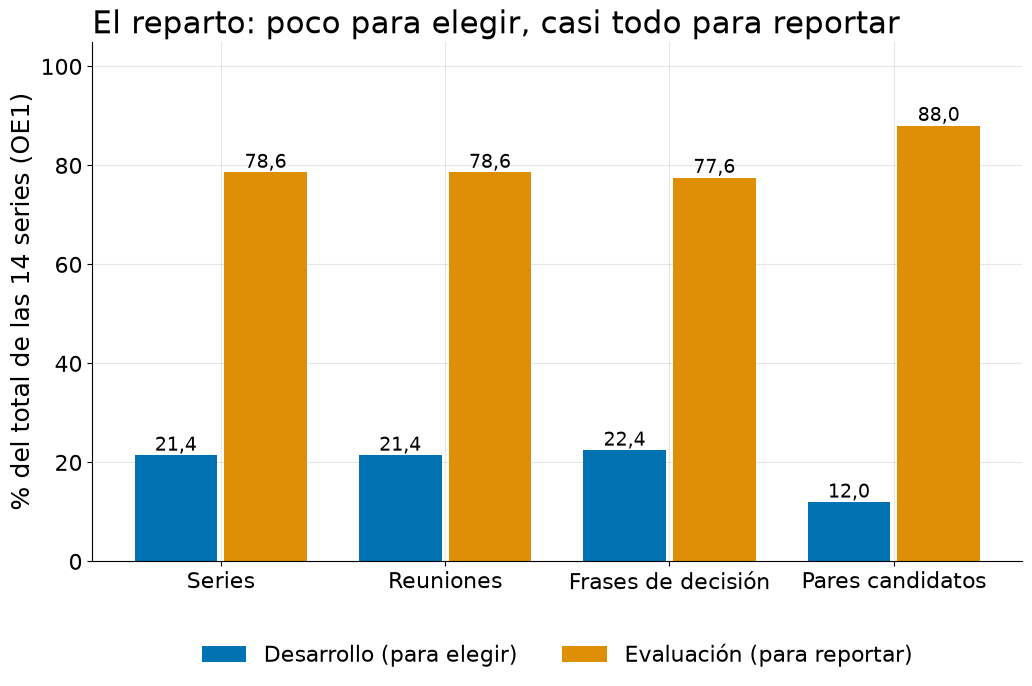

In [9]:
with video_style():
    fig = plot_grouped_bars(
        ["Series", "Reuniones", "Frases de decisión", "Pares candidatos"],
        {
            "Desarrollo (para elegir)": [
                PARTS.loc["development", f"pct_{c}"]
                for c in ("series", "meetings", "decisions", "candidates")
            ],
            "Evaluación (para reportar)": [
                PARTS.loc["evaluation", f"pct_{c}"]
                for c in ("series", "meetings", "decisions", "candidates")
            ],
        },
        ylabel="% del total de las 14 series (OE1)",
        title="El reparto: poco para elegir, casi todo para reportar",
        ylim=(0, 105),
    )
    EXPORTED.append(save_figure(fig, FIGURES_DIR / "modelos-particion-desarrollo-evaluacion.png"))
    display(fig)
    plt.close(fig)

## 3.1 Congelar antes de evaluar, y el horizonte temporal

Tres reglas protegen el conjunto de evaluación de la contaminación, el equivalente aquí de
«el conjunto de prueba se usa una sola vez»:

1. **Análisis estructural en cualquier serie; análisis de contenido solo en desarrollo.**
   Contar, medir longitudes y repartir es admisible en todas; leer textos de decisiones,
   pares candidatos o transcripciones, solo en ES2015, IS1004 y TS3009
   (`CONTRIBUTING.md` §7.7). Por eso en este notebook las series de evaluación solo aparecen
   como conteos.
2. **Todo lo ajustado en desarrollo se congela antes de tocar evaluación** y su valor queda
   registrado en un ADR o en `config/`. Es el equivalente de fijar el *pipeline* antes de
   mirar el conjunto de prueba (sección 10).
3. **Horizonte cronológico.** Una serie son cuatro reuniones sucesivas (a, b, c, d). OpenKOS las
   procesa en ese orden y las fechas de evento conservan el orden (sección 2); una
   decisión nunca se extrae «sabiendo» lo que se decidió en una reunión posterior.

**Fuga declarada.** El issue #145 documenta que dos umbrales de troceo de OpenKOS (cuándo
una fuente se parte en ventanas) se fijaron en agosto de 2026 con mediciones sobre TS3005,
una serie de **evaluación**, antes de que existiera la partición. Lo medido fue si la llamada
al modelo colapsaba, no si lo extraído coincidía con la referencia, y los umbrales no
codifican contenido; aun así se declara en lugar de omitirse
([documento 06](../docs/avances/06-jss-metodologia.md), §7–8).

## 3.2 Cifras que se parecen y no son lo mismo

Varias cantidades de ES2015 se citan en distintos documentos y no cuentan lo mismo. La tabla
las separa con el código que las produce; la regla del proyecto es que una cifra con dos
significados se declara (`CONTRIBUTING.md` §7.5).

In [10]:
REF = {s: reference_figures(load_series_reference(s)) for s in ("ES2015", "TS3009")}
SENTENCES = TABLES.series.set_index("series_id")["n_decisions"]
DISCREPANCY = pd.DataFrame(
    [
        {
            "serie": s,
            "frases de decisión (EDA, partición)": int(SENTENCES[s]),
            "filas adjudicadas": r.n_decisions + r.n_excluded,
            "decisiones de la referencia": r.n_decisions,
            "con evidencia de varios roles": r.n_multi_role,
            "excluidas por estado": ", ".join(f"{k} {v}" for k, v in r.excluded.items()),
        }
        for s, r in REF.items()
    ]
).set_index("serie")
DISCREPANCY

,"frases de decisión (EDA, partición)",filas adjudicadas,decisiones de la referencia,con evidencia de varios roles,excluidas por estado
serie,,,,,
ES2015,29,34,27,6,"no_decision 3, compuesta 2, descartar 1, sin_soporte 1"
TS3009,24,29,26,15,"no_decision 1, compuesta 2"


In [11]:
e = REF["ES2015"]
md(
    f"**Lectura.** En ES2015, **{int(SENTENCES['ES2015'])}** es el número de frases de decisión "
    f"del resumen de AMI (la unidad de la partición y del acuerdo entre anotadores) y "
    f"**{e.n_decisions}** el de decisiones de la referencia adjudicada (la unidad de OE2): al "
    "adjudicar, "
    "las frases compuestas se parten en hijas, y las que no son decisión, o no tienen soporte, "
    f"se excluyen ({e.n_excluded} filas). Los documentos 08 y 09 usan {int(SENTENCES['ES2015'])} "
    f"cuando hablan de la anotación y {e.n_decisions} cuando hablan de la referencia. Algo "
    "parecido "
    f"pasa con los roles: el cargador de la referencia cuenta {e.n_multi_role} decisiones de "
    "ES2015 "
    "con evidencia de varios roles, no las 9 que mencionaba el issue #99 (se deja como pregunta "
    "abierta en el notebook 14, §3). **Cifra vigente: la del código.**"
)

**Lectura.** En ES2015, **29** es el número de frases de decisión del resumen de AMI (la unidad de la partición y del acuerdo entre anotadores) y **27** el de decisiones de la referencia adjudicada (la unidad de OE2): al adjudicar, las frases compuestas se parten en hijas, y las que no son decisión, o no tienen soporte, se excluyen (7 filas). Los documentos 08 y 09 usan 29 cuando hablan de la anotación y 27 cuando hablan de la referencia. Algo parecido pasa con los roles: el cargador de la referencia cuenta 6 decisiones de ES2015 con evidencia de varios roles, no las 9 que mencionaba el issue #99 (se deja como pregunta abierta en el notebook 14, §3). **Cifra vigente: la del código.**

---

# 4. El *pipeline* de cada condición

**Qué se hace y por qué.** El curso pide tratar el preprocesamiento y el modelo como un solo
*pipeline*. Aquí cada condición es un *pipeline* completo, desde el material de partida hasta
la respuesta, y **lo único que cambia entre C1, C2 y C3 es la representación que se
consulta** (sección 5.3 de la propuesta). Todo lo demás es común y está fijado en
`config/experiments.toml`, sección `[shared_budget]`: así, si una condición responde mejor,
la única explicación posible es cómo organiza la información.

```
Transcripción ─► C1: fragmentos ─► BM25 + vectores ─► fusión RRF ─► K fragmentos ─┐
                                                                                   ├─► ¿alcanza el contexto?
Transcripción ─► C2: OpenKOS (modelo extractor) ─► base compilada ─► consulta ─────┤      │
                                                                                   │      ▼
Anotación humana ─► C3: la misma base, sin errores de extracción ─► consulta ──────┘   modelo generador ─► respuesta + fuentes ─► juez
(C0, diagnóstico: la pregunta va directo al modelo generador, sin ningún texto de apoyo)
```

In [12]:
C1P = CFG["retrieval"]["c1"]
RET = CFG["retrieval"]
PIPELINES = pd.DataFrame(
    {
        "C0 (diagnóstico, no es condición)": [
            "ninguno",
            "—",
            "—",
            "—",
            "—",
            "sin verificación",
            "solo la pregunta; prosa, o «no sé»",
            SB["generative_model"],
        ],
        "C1 (línea base)": [
            "transcripciones congeladas de la serie",
            f"troceo en fragmentos de turnos completos: hasta {es(C1P['max_chars'])} caracteres, "
            f"{C1P['overlap_turns']} turno compartido entre fragmentos",
            f"BM25 (léxico) + vectores densos de `{SB['embedding_model']}`",
            f"fusión RRF (k = {RET['rrf_k']}) y los {C1P['k']} mejores fragmentos",
            "mismo recorte que OpenKOS (sus funciones, portadas línea por línea)",
            "`sufficiency.md` de OpenKOS copiado byte a byte",
            "`system.md` de OpenKOS copiado byte a byte; cita con la línea `USED:`",
            SB["generative_model"],
        ],
        "C2 (la propuesta)": [
            "transcripciones de la serie, procesadas de la reunión a a la d",
            "OpenKOS extrae objetos (decisiones, temas, eventos) con un modelo extractor y guarda "
            "la fuente en bruto",
            f"índice híbrido de OpenKOS con `{SB['embedding_model']}`",
            f"`openkos query --limit {RET['answer_limit']}`, sin modificar",
            "el de OpenKOS (el mismo recorte por construcción)",
            "verificación de suficiencia de OpenKOS (ver el riesgo de la sección 5.6)",
            "OpenKOS, sin modificar",
            SB["generative_model"],
        ],
        "C3 (referencia humana)": [
            "anotación humana adjudicada de la serie (OE1)",
            "los mismos objetos que C2, escritos desde la anotación: sin errores de extracción",
            "igual que C2",
            "igual que C2",
            "igual que C2",
            "igual que C2",
            "igual que C2",
            SB["generative_model"],
        ],
    },
    index=[
        "1. Material de partida",
        "2. Preparación",
        "3. Índice",
        "4. Recuperación",
        "5. Presupuesto de contexto",
        "6. ¿Alcanza el contexto?",
        "7. Respuesta",
        "8. Modelo generador",
    ],
)
PIPELINES

,"C0 (diagnóstico, no es condición)",C1 (línea base),C2 (la propuesta),C3 (referencia humana)
1. Material de partida,ninguno,transcripciones congeladas de la serie,"transcripciones de la serie, procesadas de la reunión a a la d",anotación humana adjudicada de la serie (OE1)
2. Preparación,—,"troceo en fragmentos de turnos completos: hasta 1.200 caracteres, 1 turno compartido entre fragmentos","OpenKOS extrae objetos (decisiones, temas, eventos) con un modelo extractor y guarda la fuente en bruto","los mismos objetos que C2, escritos desde la anotación: sin errores de extracción"
3. Índice,—,BM25 (léxico) + vectores densos de `bge-m3`,índice híbrido de OpenKOS con `bge-m3`,igual que C2
4. Recuperación,—,fusión RRF (k = 60) y los 5 mejores fragmentos,"`openkos query --limit 5`, sin modificar",igual que C2
5. Presupuesto de contexto,—,"mismo recorte que OpenKOS (sus funciones, portadas línea por línea)",el de OpenKOS (el mismo recorte por construcción),igual que C2
6. ¿Alcanza el contexto?,sin verificación,`sufficiency.md` de OpenKOS copiado byte a byte,verificación de suficiencia de OpenKOS (ver el riesgo de la sección 5.6),igual que C2
7. Respuesta,"solo la pregunta; prosa, o «no sé»",`system.md` de OpenKOS copiado byte a byte; cita con la línea `USED:`,"OpenKOS, sin modificar",igual que C2
8. Modelo generador,qwen3:8b,qwen3:8b,qwen3:8b,qwen3:8b


**Lectura.** C1 es una línea base **honesta**: tiene su propio recuperador híbrido y sus
parámetros se ajustaron con datos (sección 6), no se fijaron a ojo, porque una línea base
débil haría que cualquier propuesta pareciera buena. C2 y C3 responden a través de OpenKOS
tal como es (se evalúa el instrumento como responde), y C1 copia sus instrucciones de
respuesta para que la redacción no sea la causa de una diferencia
([ADR 0006](../docs/decisions/0006-adr-c1-rag-separado-con-respuesta-de-openkos.md)). **C3 aún
no se puede ejecutar**: depende de la anotación humana de las series, y su condición lanza
hoy un error explícito de «sin implementar»; no hay ninguna cifra de C3 en este notebook.

## 4.1 Lo que se comparte: presupuesto común

In [13]:
SHARED = pd.DataFrame(
    [
        (
            "Modelo generador",
            SB["generative_model"],
            "Mismo modelo que redacta la respuesta en C0, C1, C2 y C3",
        ),
        (
            "Modelo de *embeddings*",
            SB["embedding_model"],
            "Multilingüe; el mismo en las tres condiciones",
        ),
        (
            "Ventana de contexto",
            f"{es(SB['context_window_tokens'])} tokens",
            "Valor por defecto de OpenKOS (`num_ctx`)",
        ),
        (
            "Largo máximo de respuesta",
            f"{es(SB['max_generation_tokens'])} tokens",
            "Valor por defecto de OpenKOS (`num_predict`)",
        ),
        (
            "`temperature`",
            es(SB["temperature"], 1),
            "Azar bajo: respuestas casi siempre iguales; OpenKOS lo deja sin fijar, aquí se fija",
        ),
        (
            "`top_p`",
            es(SB["top_p"], 1),
            "Configurado, pero C1 **no lo envía** porque OpenKOS tampoco, para que las "
            "condiciones reciban las mismas opciones",
        ),
        ("Semilla", str(SB["seed"]), "Hace repetible la corrida (misma semilla, mismo resultado)"),
        (
            "Corridas por configuración",
            str(SB["runs_per_config"]),
            "Mínimo de la propuesta: se informa media y dispersión",
        ),
        (
            "Bloques de contexto en C2 y C3",
            str(RET["answer_limit"]),
            "`--limit` de `openkos query`: presupuesto de **texto** igual, no K igual (ADR 0007)",
        ),
    ],
    columns=["parámetro", "valor", "por qué"],
).set_index("parámetro")
SHARED

,valor,por qué
parámetro,,
Modelo generador,qwen3:8b,"Mismo modelo que redacta la respuesta en C0, C1, C2 y C3"
Modelo de *embeddings*,bge-m3,Multilingüe; el mismo en las tres condiciones
Ventana de contexto,12.288 tokens,Valor por defecto de OpenKOS (`num_ctx`)
Largo máximo de respuesta,8.192 tokens,Valor por defecto de OpenKOS (`num_predict`)
`temperature`,"0,1","Azar bajo: respuestas casi siempre iguales; OpenKOS lo deja sin fijar, aquí se fija"
`top_p`,"0,9","Configurado, pero C1 **no lo envía** porque OpenKOS tampoco, para que las condiciones reciban las mismas opciones"
Semilla,42,"Hace repetible la corrida (misma semilla, mismo resultado)"
Corridas por configuración,3,Mínimo de la propuesta: se informa media y dispersión
Bloques de contexto en C2 y C3,5,"`--limit` de `openkos query`: presupuesto de **texto** igual, no K igual (ADR 0007)"


La configuración deja anotado un segundo punto de escala, `qwen3:32b`
(`generative_model_large`), como **extensión** para la hipótesis H3 y no como corrida
comprometida. Además, la etiqueta exacta del modelo (su huella digital en Ollama) se registra
en el manifiesto de cada corrida (sección 8), porque una etiqueta puede apuntar a otros pesos.

---

# 5. Modelos por rol: candidatos, selección y evidencia

**Qué se hace y por qué.** El curso pide justificar la elección del modelo en relación con el
problema. Aquí hay cuatro **roles** de modelo, cada uno con su propia pregunta de selección, y
solo dos de ellos se eligieron comparando candidatos con una prueba propia (el extractor y el
juez). Se dice con claridad cuál es cuál, y qué evidencia es de esta tesis y cuál viene de
OpenKOS.

| Rol | Dónde interviene | Modelo | ¿Se comparó con alternativas aquí? |
|---|---|---|---|
| **Generador de respuestas** | C0, C1, C2 y C3 | `qwen3:8b` | No: es el modelo compartido de la propuesta (§5.3). La evidencia de que es una buena elección viene de OpenKOS (sección 5.5) |
| **Embeddings** | Recuperación en C1, C2 y C3; alineación del Experimento A | `bge-m3` | No: se hereda de OpenKOS, que lo eligió por fiabilidad |
| **Extractor de C2** | Construye la base compilada | `qwen3:8b` hoy; **decisión pendiente** (#143) | Sí: *screen* de cuatro modelos (sección 5.3) |
| **Juez** | Califica cada respuesta | `gpt-oss:20b` | Sí: calibración de tres candidatos (sección 5.4) |

## 5.1 Generador de respuestas y *embeddings*

**Generador.** `qwen3:8b` responde en todas las condiciones. Se eligió porque la propuesta
exige el mismo modelo generativo en las tres condiciones, porque corre en local sin enviar
datos a terceros, y porque es el modelo por defecto de OpenKOS (decidido por una medición,
ADR-0001 de OpenKOS), de modo que C2 y C3 responden «tal como responde OpenKOS». La tesis
**no comparó otros generadores**; esa es una limitación declarada (sección 11). OpenKOS sí
lo hizo para su paso de respuesta y no encontró ganador (sección 5.5).

**Embeddings.** `bge-m3` es multilingüe y OpenKOS lo adoptó por fiabilidad: el modelo que
tenía antes hacía fallar el servidor de modelos de forma no determinista en documentos
largos, y `bge-m3` no falló en esa medición (ADR-0006 de OpenKOS). Se mantiene el mismo
modelo en las tres condiciones y en el protocolo de alineación.

## 5.2 Un parámetro que el modelo no controla: la ventana de lectura

El modelo lee a lo más lo que cabe en su ventana, y lo que cabe se reparte entre las
instrucciones, la pregunta, los bloques recuperados y la reserva para responder. Por eso el
mismo `qwen3:8b` "ve" cosas distintas en C1 y en C2 si no se iguala el presupuesto de texto;
es lo que el [ADR 0007](../docs/decisions/0007-adr-ajuste-c1-y-presupuesto-de-contexto.md)
iguala y lo que la sección 6.1 usa para ajustar C1.

## 5.3 Extractor de C2: el *screen* de cuatro modelos

**Pregunta.** OpenKOS necesita un modelo para extraer las decisiones de cada transcripción.
Hay cuatro candidatos de la familia `qwen3`: `qwen3:8b` (el modelo base y el generador
compartido), `qwen3:14b`, `qwen3.6:27b` y `qwen3.6:35b-a3b`. **Método:** *screen* con regla de
selección **prerregistrada** (fijada antes de la primera corrida; prerregistro en OpenKOS,
PR #1554): un candidato avanza solo si, frente a `qwen3:8b` y **en las dos series de
desarrollo**, mejora el F1 con τ = 0,60 por un margen mayor que el ruido entre corridas, no
pierde cobertura, no falla más que el modelo base y no inunda de decisiones. Las corridas
(5 por modelo y serie, y 15 nuevas para el que avanzó) las hizo OpenKOS; aquí se leen sin
modificarlas y se les aplica la regla con código de la tesis. En el notebook 15 se verificó
que el puntaje de la tesis coincide con el de OpenKOS en las 108 combinaciones.

In [14]:
SCREEN_SCORED = json.loads((SCREEN_DIR / "screen" / "scored.json").read_text(encoding="utf-8"))
CONFIRM_SCORED = json.loads((SCREEN_DIR / "confirm" / "scored.json").read_text(encoding="utf-8"))
BASELINE = "qwen3:8b"
Q_SCREEN = screen_quality(SCREEN_SCORED, tau=SELECTION_TAU, phase="screen (5 corridas)")
Q_CONFIRM = screen_quality(CONFIRM_SCORED, tau=SELECTION_TAU, phase="confirmatoria (15 corridas)")
RULE_SCREEN = screen_rule(Q_SCREEN, baseline=BASELINE)
RULE_CONFIRM = screen_rule(Q_CONFIRM, baseline=BASELINE)
WINNER_SCREEN, WINNER_CONFIRM = screen_winner(RULE_SCREEN), screen_winner(RULE_CONFIRM)
COST_SCREEN = screen_costs(SCREEN_SCORED, phase="screen", baseline=BASELINE)
COST_CONFIRM = screen_costs(CONFIRM_SCORED, phase="confirmatoria", baseline=BASELINE)
MODEL_ORDER = ["qwen3:8b", "qwen3:14b", "qwen3.6:27b", "qwen3.6:35b-a3b"]


def screen_table(quality, costs):
    ratio = {(c.model, c.activity.split()[-1]): c.ratio for c in costs}
    rows = []
    for series in ("ES2015", "TS3009"):
        for model in MODEL_ORDER:
            hit = quality[(quality["model"] == model) & (quality["series"] == series)]
            if hit.empty:
                continue
            q = hit.iloc[0]
            rows.append(
                {
                    "serie": series,
                    "modelo": model,
                    "F1 (mín-máx)": f"{es(q.f1, 3)} ({es(q.f1_min, 3)}-{es(q.f1_max, 3)})",
                    "cobertura": es(q.recall, 3),
                    "decisiones por reunión": es(q.decisions_per_meeting, 1),
                    "reuniones fallidas": f"{int(q.failed_meeting_runs)} de {int(q.meeting_runs)}",
                    "segundos por corrida": es(q.seconds_per_run),
                    "veces el tiempo del 8b": es(ratio[(model, series)], 1),
                }
            )
    return pd.DataFrame(rows).set_index(["serie", "modelo"])


md(f"**Screen (5 corridas por modelo y serie), con τ = {es(SELECTION_TAU, 2)}.**")
screen_table(Q_SCREEN, COST_SCREEN)

**Screen (5 corridas por modelo y serie), con τ = 0,60.**

F1 (mín-máx) cobertura decisiones por reunión reuniones fallidas segundos por corrida veces el tiempo del 8b
serie  modelo                                                                                                                              
ES2015 qwen3:8b         0,290 (0,250-0,349)     0,481                   15,7            0 de 20                  168                    1,0
       qwen3:14b        0,387 (0,324-0,421)     0,548                   12,3            0 de 20                  216                    1,3
       qwen3.6:27b      0,485 (0,413-0,542)     0,563                    8,9            0 de 20                  581                    3,5
       qwen3.6:35b-a3b  0,461 (0,413-0,554)     0,652                   12,6            0 de 20                   90                    0,5
TS3009 qwen3:8b         0,300 (0,252-0,336)     0,654                   21,9            0 de 20                  268                    1,0
       qwen3:14b        0,493 (0,462-0,543)     0,785                   14,2            0 de 20                  223                    0,8
       qwen3.6:27b      0,457 (0,379-0,512)     0,808                   16,6            0 de 20                  883                    3,3
       qwen3.6:35b-a3b  0,405 (0,377-0,438)     0,838                   20,4            0 de 20                  187                    0,7

In [15]:
def rule_table(rule):
    return pd.DataFrame(
        {
            "candidato": rule["candidate"],
            "serie": rule["series"],
            "ganancia de F1": rule["d_f1"].round(3),
            f"exigido max({es(MARGIN_FLOOR, 2)}; ruido)": rule["needed"].round(3),
            "1 margen": rule["margin_ok"],
            "2 cobertura": rule["recall_ok"],
            f"3 fallas (≤ max({FAILURE_FLOOR}; las del 8b))": rule["failures_ok"],
            f"4 volumen (≤ {es(VOLUME_FACTOR, 2)}x el del 8b)": rule["volume_ok"],
            "cumple las cuatro": rule["passes"],
        }
    ).set_index(["candidato", "serie"])


md("**Regla prerregistrada aplicada al *screen*.**")
display(rule_table(RULE_SCREEN))
md("**Confirmatoria (15 corridas nuevas) del modelo que avanzó, frente a `qwen3:8b`.**")
display(screen_table(Q_CONFIRM, COST_CONFIRM))
rule_table(RULE_CONFIRM)

**Regla prerregistrada aplicada al *screen*.**

ganancia de F1  exigido max(0,05; ruido)  1 margen  2 cobertura  3 fallas (≤ max(2; las del 8b))  4 volumen (≤ 1,10x el del 8b)  \
candidato       serie                                                                                                                                     
qwen3.6:27b     ES2015           0.194                     0.130      True         True                             True                           True   
                TS3009           0.157                     0.133      True         True                             True                           True   
qwen3.6:35b-a3b ES2015           0.171                     0.141      True         True                             True                           True   
                TS3009           0.105                     0.084      True         True                             True                           True   
qwen3:14b       ES2015           0.097                     0.099     False         True                             True                           True   
                TS3009           0.192                     0.084      True         True                             True                           True   

                        cumple las cuatro  
candidato       serie                      
qwen3.6:27b     ES2015               True  
                TS3009               True  
qwen3.6:35b-a3b ES2015               True  
                TS3009               True  
qwen3:14b       ES2015              False  
                TS3009               True

**Confirmatoria (15 corridas nuevas) del modelo que avanzó, frente a `qwen3:8b`.**

F1 (mín-máx) cobertura decisiones por reunión reuniones fallidas segundos por corrida veces el tiempo del 8b
serie  modelo                                                                                                                          
ES2015 qwen3:8b     0,289 (0,255-0,322)     0,474                   15,4            1 de 60                  166                    1,0
       qwen3.6:27b  0,470 (0,394-0,554)     0,575                    9,8            0 de 60                  598                    3,6
TS3009 qwen3:8b     0,303 (0,248-0,400)     0,646                   21,3            6 de 60                  489                    1,0
       qwen3.6:27b  0,474 (0,429-0,522)     0,818                   15,9            4 de 60                  895                    1,8

ganancia de F1  exigido max(0,05; ruido)  1 margen  2 cobertura  3 fallas (≤ max(2; las del 8b))  4 volumen (≤ 1,10x el del 8b)  cumple las cuatro
candidato   serie                                                                                                                                                     
qwen3.6:27b ES2015           0.181                     0.160      True         True                             True                           True               True
            TS3009           0.172                     0.152      True         True                             True                           True               True

In [16]:
ratio27 = {c.activity.split()[-1]: c.ratio for c in COST_CONFIRM if c.model == WINNER_SCREEN}
gain27 = RULE_CONFIRM.set_index("series")["d_f1"]
fail8 = Q_CONFIRM[Q_CONFIRM["model"] == BASELINE].set_index("series")
r14 = RULE_SCREEN.set_index(["candidate", "series"]).loc[("qwen3:14b", "ES2015")]
md(
    f"**Lectura.** Con la regla prerregistrada avanza `{WINNER_SCREEN}`, y las 15 corridas nuevas "
    f"{'lo confirman' if WINNER_CONFIRM == WINNER_SCREEN else 'NO lo confirman'}: gana "
    f"{es(gain27['ES2015'], 2)} de F1 en ES2015 y {es(gain27['TS3009'], 2)} en TS3009 sobre "
    f"`{BASELINE}`, "
    f"sin perder cobertura. **El costo es el tiempo**: tarda {es(ratio27['ES2015'], 1)} veces más "
    f"por corrida en ES2015 y {es(ratio27['TS3009'], 1)} veces más en TS3009 (en esta serie el "
    f"tiempo del 8b está inflado por sus {int(fail8.loc['TS3009', 'failed_meeting_runs'])} "
    "reuniones "
    f"fallidas de {int(fail8.loc['TS3009', 'meeting_runs'])}, casi todas por tope de generación). "
    f"`qwen3:14b` queda fuera por un margen mínimo en ES2015 (la ganancia de F1 es "
    f"{es(r14['d_f1'], 3)} y se exigían {es(r14['needed'], 3)}): "
    "es la regla operando como se registró, no evidencia de que sea peor. "
    "**Esto no es todavía la decisión del extractor**: la ganancia sale de dos series de "
    "desarrollo, "
    "y el puntaje con τ = 0,60 incluye parecido temático (en el control con salidas de otro equipo "
    "la cobertura es alrededor de 0,3; notebook 15, §6.2). La elección queda abierta (#143, "
    "sección 10)."
)

**Lectura.** Con la regla prerregistrada avanza `qwen3.6:27b`, y las 15 corridas nuevas lo confirman: gana 0,18 de F1 en ES2015 y 0,17 en TS3009 sobre `qwen3:8b`, sin perder cobertura. **El costo es el tiempo**: tarda 3,6 veces más por corrida en ES2015 y 1,8 veces más en TS3009 (en esta serie el tiempo del 8b está inflado por sus 6 reuniones fallidas de 60, casi todas por tope de generación). `qwen3:14b` queda fuera por un margen mínimo en ES2015 (la ganancia de F1 es 0,097 y se exigían 0,099): es la regla operando como se registró, no evidencia de que sea peor. **Esto no es todavía la decisión del extractor**: la ganancia sale de dos series de desarrollo, y el puntaje con τ = 0,60 incluye parecido temático (en el control con salidas de otro equipo la cobertura es alrededor de 0,3; notebook 15, §6.2). La elección queda abierta (#143, sección 10).

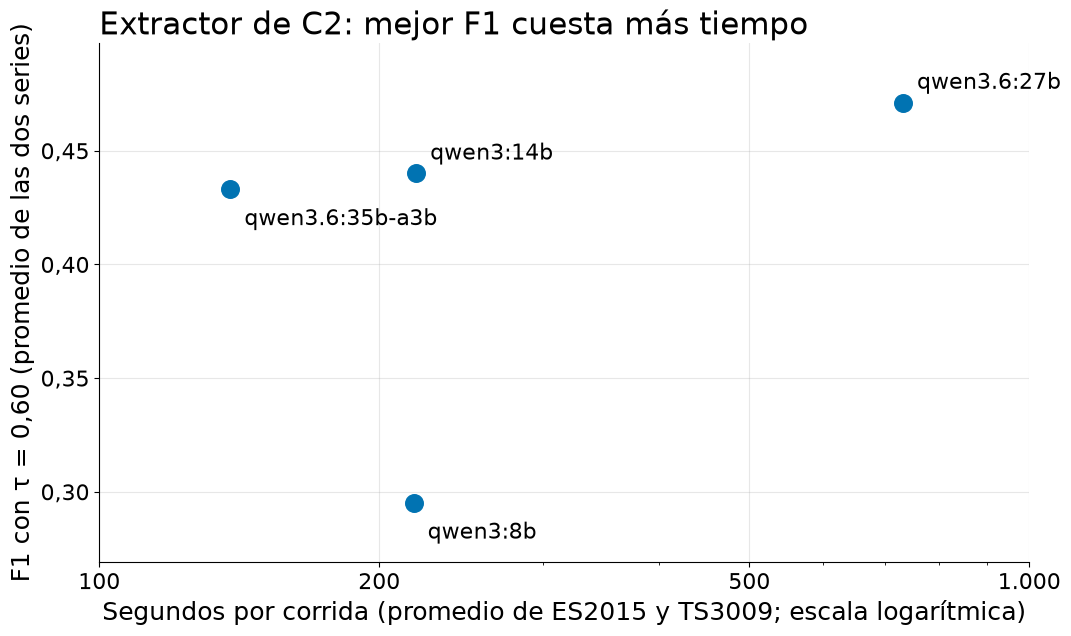

In [17]:
q_screen_models = screen_by_model(Q_SCREEN).reindex(MODEL_ORDER)
with video_style():
    fig = plot_labeled_scatter(
        [
            (
                m,
                float(q_screen_models.loc[m, "seconds_per_run"]),
                float(q_screen_models.loc[m, "f1"]),
            )
            for m in MODEL_ORDER
        ],
        xlabel="Segundos por corrida (promedio de ES2015 y TS3009; escala logarítmica)",
        ylabel="F1 con τ = 0,60 (promedio de las dos series)",
        title="Extractor de C2: mejor F1 cuesta más tiempo",
        log_x=True,
    )
    EXPORTED.append(save_figure(fig, FIGURES_DIR / "modelos-screen-extraccion-f1-costo.png"))
    display(fig)
    plt.close(fig)

**Lectura de la confirmatoria, en dos gráficos.** F1 y tiempo por corrida de `qwen3:8b` y del
modelo que avanzó, en cada serie; se dibujan por separado para no mezclar escalas. El notebook 20
amplía esta comparación (diferencias de F1 y *recall*, y reuniones fallidas).

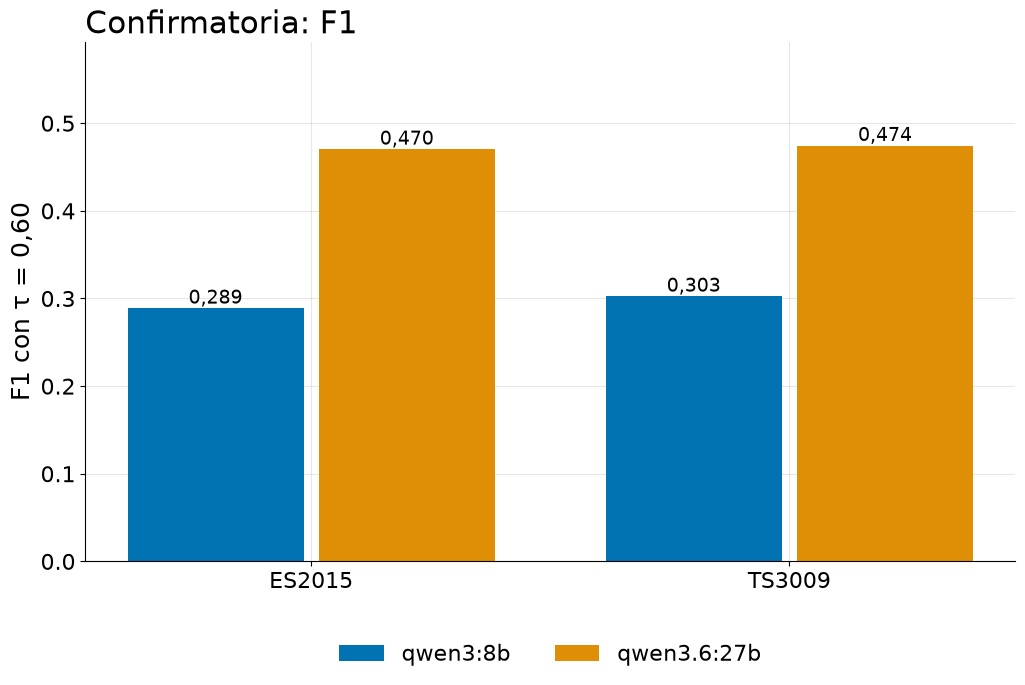

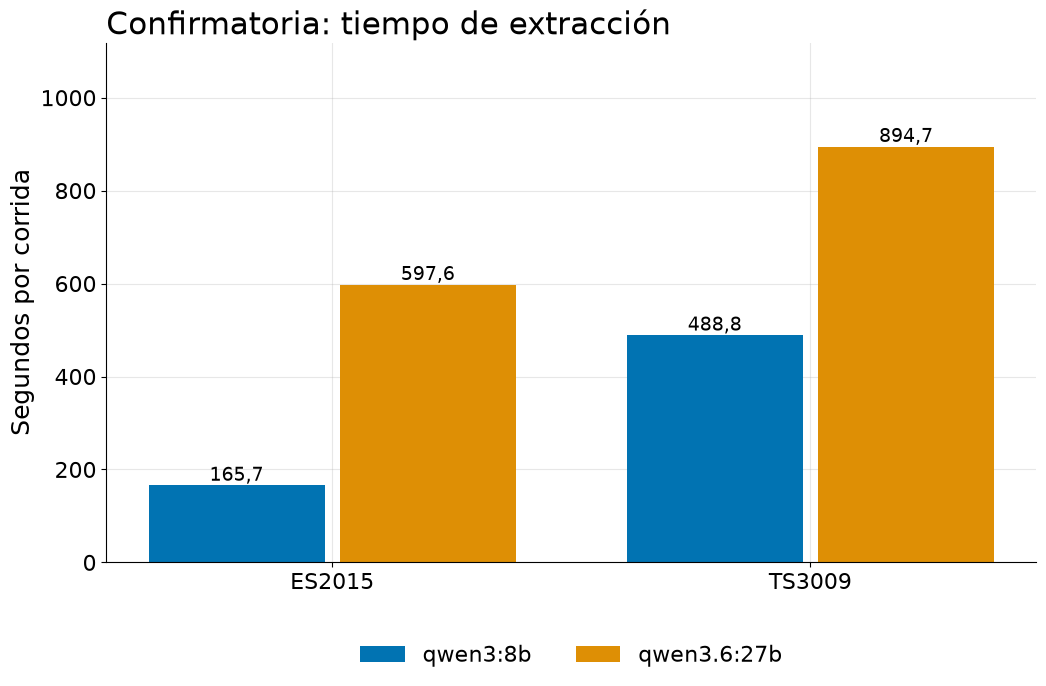

In [18]:
CONFIRM_CMP = compare_to_baseline(Q_CONFIRM, baseline=BASELINE, candidate=WINNER_SCREEN)
f1_top = float(CONFIRM_CMP[["f1_baseline", "f1_candidate"]].to_numpy().max())
sec_top = float(CONFIRM_CMP[["seconds_baseline", "seconds_candidate"]].to_numpy().max())
with video_style():
    for columns, ylabel, title, top, decimals in (
        (
            ("f1_baseline", "f1_candidate"),
            f"F1 con τ = {es(SELECTION_TAU, 2)}",
            "Confirmatoria: F1",
            f1_top,
            3,
        ),
        (
            ("seconds_baseline", "seconds_candidate"),
            "Segundos por corrida",
            "Confirmatoria: tiempo de extracción",
            sec_top,
            1,
        ),
    ):
        fig = plot_grouped_bars(
            list(CONFIRM_CMP.index),
            {BASELINE: list(CONFIRM_CMP[columns[0]]), WINNER_SCREEN: list(CONFIRM_CMP[columns[1]])},
            ylabel=ylabel,
            title=title,
            ylim=(0, top * 1.25),
            decimals=decimals,
        )
        display(fig)
        plt.close(fig)

## 5.4 Juez: calibración de tres candidatos

**Pregunta.** Se necesita un modelo que califique ~900 respuestas (100 preguntas como mínimo ×
3 condiciones × 3 corridas). El juez es la **regla de medir**, no un modelo bajo prueba, así
que se lo valida contra personas antes de usarlo. **Método:** umbrales **prerregistrados**
(`[judge.calibration]` en la configuración, escritos antes de correr ningún candidato) sobre
un conjunto propio de 42 respuestas de ES2015 etiquetadas a mano, porque ningún ranking
público mide esta tarea. Un candidato debe cumplir **todos** los umbrales; si varios cumplen,
gana el más rápido. Además debe ser de una **familia distinta** de la del modelo generador y
extractor (Qwen) para evitar el sesgo de preferir sus propias respuestas; por la misma razón se
excluyó la familia Gemma, que OpenKOS usa en sus propios jueces internos.

In [19]:
JUDGE = load_calibration_results(JUDGE_RESULTS_PATH)
HUMAN = json.loads(
    (PROJECT_ROOT / "reports" / "judge-calibration" / "acuerdo-humano.json").read_text(
        encoding="utf-8"
    )
)
THRESHOLDS = pd.Series(
    {
        "kappa con las personas (correcta) ≥": JC["min_kappa_correct"],
        "consistencia al invertir el orden ≥": JC["min_position_consistency"],
        "consistencia entre semillas ≥": JC["min_seed_consistency"],
        "accuracy en E4 ≥": JC["min_e4_accuracy"],
        "salidas válidas ≥": JC["min_json_valid_rate"],
        "cambio de veredicto al alargar una respuesta errada ≤": JC["max_verbosity_flip_rate"],
    }
)
JUDGE_TABLE = pd.DataFrame(
    [
        {
            "candidato": c.model,
            "kappa": es(c.kappa, 3),
            "orden": es(c.position_consistency, 3),
            "semillas": es(c.seed_consistency, 2),
            "accuracy E4": es(c.e4_accuracy, 2),
            "salidas válidas": es(c.json_valid_rate, 2),
            "cambio por verbosidad": es(c.verbosity_flip_rate, 2),
            "latencia por llamada (s)": es(c.latency_seconds, 1),
            "fallan": ", ".join(JUDGE.failures[c.model]) or "ninguno",
        }
        for c in JUDGE.candidates
    ]
).set_index("candidato")
md("**Umbrales prerregistrados** (fijados antes de correr ningún candidato):")
display(THRESHOLDS.map(lambda v: es(v, 2)).to_frame("umbral"))
md(f"**Resultados** ({JUDGE.n_items} ítems de ES2015, desarrollo):")
JUDGE_TABLE

**Umbrales prerregistrados** (fijados antes de correr ningún candidato):

,umbral
kappa con las personas (correcta) ≥,"0,70"
consistencia al invertir el orden ≥,"0,90"
consistencia entre semillas ≥,"0,95"
accuracy en E4 ≥,"0,80"
salidas válidas ≥,"0,99"
cambio de veredicto al alargar una respuesta errada ≤,"0,10"


**Resultados** (42 ítems de ES2015, desarrollo):

,kappa,orden,semillas,accuracy E4,salidas válidas,cambio por verbosidad,latencia por llamada (s),fallan
candidato,,,,,,,,
mistral-small3.2:24b,"0,951","0,952","1,00","1,00","1,00","0,06","5,5",ninguno
atla/selene-mini:q8_0,"0,485","0,738","1,00","1,00","1,00","0,00","3,0","kappa_correct, position_consistency"
gpt-oss:20b,"0,951","0,952","1,00","1,00","1,00","0,00","3,2",ninguno


In [20]:
meeting_all = [c for c in JUDGE.candidates if not JUDGE.failures[c.model]]
failed = [c for c in JUDGE.candidates if JUDGE.failures[c.model]]
FAIL_NAMES = {
    "kappa_correct": "el acuerdo con las personas",
    "position_consistency": "la estabilidad ante el orden de presentación",
}
k_correct = next(c for c in HUMAN["columns"] if c["column"] == "correct")
k_supported = next(c for c in HUMAN["columns"] if c["column"] == "evidence_supported")
md(
    f"**Lectura.** {len(meeting_all)} de {len(JUDGE.candidates)} candidatos cumplen todos los "
    "umbrales "
    f"({', '.join(f'`{c.model}`' for c in meeting_all)}), con el mismo kappa de "
    f"{es(meeting_all[0].kappa, 3)}; "
    f"la regla fijada de antemano desempata por rapidez y gana `{JUDGE.selected}` "
    f"({es(next(c.latency_seconds for c in JUDGE.candidates if c.model == JUDGE.selected), 1)} s "
    "por llamada), "
    "de la familia OpenAI de pesos abiertos, distinta de Qwen. "
    f"`{failed[0].model}` queda fuera porque no cumple "
    f"{' ni '.join(FAIL_NAMES[f] for f in JUDGE.failures[failed[0].model])}. "
    "Se descartaron además, sin correrlos, "
    "`phi4:14b` (su contexto de 16 K no alcanza), Llama 3.3 70B (43 GB, no cabe en el equipo) y "
    "las "
    "destilaciones de DeepSeek-R1 de base Qwen (heredan la familia del extractor; notebook 05, "
    "§3.2). "
    f"Una segunda persona etiquetó {k_correct['n_items']} ítems por separado y coincidió en "
    f"{k_correct['n_agree']} sobre «correcta» (kappa {es(k_correct['kappa'], 2)}) y en "
    f"{k_supported['n_agree']} "
    f"sobre «respaldada» (kappa {es(k_supported['kappa'], 3)}). **Límite:** son {JUDGE.n_items} "
    "ítems de una "
    "sola serie; el identificador de cada ítem delataba cómo se generó la respuesta, por lo que "
    "el acuerdo "
    "podría estar algo inflado (notebook 05, §9.2). Como salvaguarda, una persona vuelve a juzgar "
    "el "
    f"{pct(EVAL['human_validation_fraction'], 0)} de las respuestas del experimento y el kappa "
    "debe alcanzar "
    f"{es(JC['min_kappa_correct'], 2)}."
)

**Lectura.** 2 de 3 candidatos cumplen todos los umbrales (`mistral-small3.2:24b`, `gpt-oss:20b`), con el mismo kappa de 0,951; la regla fijada de antemano desempata por rapidez y gana `gpt-oss:20b` (3,2 s por llamada), de la familia OpenAI de pesos abiertos, distinta de Qwen. `atla/selene-mini:q8_0` queda fuera porque no cumple el acuerdo con las personas ni la estabilidad ante el orden de presentación. Se descartaron además, sin correrlos, `phi4:14b` (su contexto de 16 K no alcanza), Llama 3.3 70B (43 GB, no cabe en el equipo) y las destilaciones de DeepSeek-R1 de base Qwen (heredan la familia del extractor; notebook 05, §3.2). Una segunda persona etiquetó 15 ítems por separado y coincidió en 15 sobre «correcta» (kappa 1,00) y en 14 sobre «respaldada» (kappa 0,865). **Límite:** son 42 ítems de una sola serie; el identificador de cada ítem delataba cómo se generó la respuesta, por lo que el acuerdo podría estar algo inflado (notebook 05, §9.2). Como salvaguarda, una persona vuelve a juzgar el 20 % de las respuestas del experimento y el kappa debe alcanzar 0,70.

## 5.5 Lo que OpenKOS usa por tarea (evidencia externa)

OpenKOS es un instrumento desarrollado antes por uno de los integrantes del equipo
([ADR 0003](../docs/decisions/0003-adr-openkos-as-instrument.md)). Lo que sigue **no es
evidencia de esta tesis**: son hechos documentados en el repositorio de OpenKOS, que se
verificaron leyendo su código y sus documentos (versión 0.6.0 más 35 commits posteriores,
`354fe2ad`), no se importa ningún código de OpenKOS, y las corridas de esos *screens* no se
reprodujeron aquí. Se citan porque explican qué modelo interviene en cada paso de C2 y C3.

| Tarea de OpenKOS | Modelo por defecto | Qué decidió OpenKOS y con qué evidencia |
|---|---|---|
| Extracción (`extraction`) y respuesta (síntesis) | `qwen3:8b` | ADR-0001: elegido por una medición con tres candidatos de 7–8 B. Un *screen* del paso de respuesta (epic jasonssdev/openkos#1556, issue #1560) **no encontró ganador** y `qwen3:8b` se queda |
| Embeddings | `bge-m3` | ADR-0006: elegido por fiabilidad (cero fallos entre 8 y 100 mil caracteres) |
| Jueces internos de **adjudicación** y **contradicción** | `gemma4:26b-a4b` | ADR-0047 (issue #1269): ganó ambos roles en un barrido prerregistrado. Solo actúan al compilar, es decir, afectan a C2 |
| **Verificación de suficiencia** de `query` | `gemma4:26b-a4b` **solo en la rama principal** (ADR-0076, issue #1560) | No está en la 0.6.0. En el *screen* ganó con +0,096 de diferencia pareada sobre `qwen3:8b` en 96 ítems. Cambia **cómo responde C2** (sección 5.6) |
| Extracción de conceptos: modelo y tamaño de ventana | `qwen3:8b`, ventana de 4.000 caracteres | Issues #1557 y #1558: **sin ganador**, no se adopta nada |
| Pase de decisiones de transcripciones (el que mide la sección 5.3) | `qwen3:8b` | El *screen* de la sección 5.3 es de este paso. El issue #1561 confirmó con 15 corridas a `qwen3.6:35b-a3b` y **no pasa la regla** (margen de F1 de +0,164 frente a 0,192 exigido en ES2015 y +0,070 frente a 0,165 en TS3009); tampoco se adopta nada |

Los *keys* por tarea que acepta el archivo de configuración de un espacio de trabajo de
OpenKOS (`models:`) son `extraction`, `adjudication`, `edge_typing`, `volatility_typing`,
`contradiction` y `sufficiency`. Una clave explícita en el espacio de trabajo **gana sobre
el valor por defecto empaquetado**; una clave nula lo rechaza y vuelve al modelo global.

## 5.6 Un riesgo para la igualdad entre condiciones: la verificación de suficiencia

C1 copia las instrucciones de OpenKOS y hace la verificación de suficiencia con el mismo
`qwen3:8b` que redacta. Si C2 y C3 se ejecutaran con una versión de OpenKOS que ya empaqueta
`gemma4:26b-a4b` para esa verificación (la rama principal hoy, no la 0.6.0), **C2 y C3
decidirían con otro modelo si el contexto alcanza para responder** y las condiciones
dejarían de ser iguales salvo en la representación: la abstención de C2 dependería de otro
modelo. Hay dos salidas, y la elección queda para el equipo al fijar la versión (#94):
**fijar una versión sin esa verificación** (la 0.6.0) o **fijar `models: {sufficiency:
qwen3:8b}`** en el espacio de trabajo de C2 y C3 (la precedencia lo permite). Además, esa
verificación hace que una primera consulta cambie de modelo en memoria una vez, lo que
cambiaría los tiempos.

**Controles de comparabilidad por revisar antes de la corrida formal.** Además de la
verificación de suficiencia, hay cuatro comprobaciones que el diseño todavía no cierra:

1. **Huella del generador en cada corrida.** Confirmar que C1 y C2 usan el mismo `qwen3:8b`
   por su huella en Ollama, y no solo por la etiqueta (sección 8.2).
2. **Versión y huella del modelo de *embeddings*.** `bge-m3` está declarado como compartido,
   pero la versión y la huella de cada backend aún no se registran.
3. **Texto efectivo entregado, no solo K.** Comparar lo que realmente llega al generador en C1
   y en C2 tras el recorte de contexto (ADR 0007), y no únicamente K o el límite nominal.
4. **Instrucciones copiadas de OpenKOS.** Revisar que las menciones a *bundle* y a objetos en
   los *prompts* de respuesta de C1 no favorezcan a C2 (ADR 0006).

El notebook 20 ordena estos controles junto con los de las secciones 4, 8.2, 9 y 11 en una tabla
de referencia.


---

# 6. Búsqueda de parámetros (los «hiperparámetros» del curso)

**Qué se hace y por qué.** Aquí hay parámetros que se **eligen** con datos y otros que se
**fijan** por diseño. Para cada uno se nombra el método explícitamente. El principio común:
todo lo que se ajusta, se ajusta en **series de desarrollo**, con una regla escrita **antes**
de correr, y queda congelado antes de tocar evaluación.

## 6.1 Fragmento y K de C1: *grid search* con regla prerregistrada

**Método: *grid search*** (se prueban todas las combinaciones de una grilla). Se barren el
tamaño máximo del fragmento, los turnos compartidos entre fragmentos consecutivos y el número
de fragmentos entregados (K). La métrica es el ***recall* de evidencia**: qué parte de los
pasajes que respaldan la respuesta llega al modelo, medida sobre las preguntas de ES2015 con
evidencia de referencia. No interviene ningún modelo generativo. La regla de selección está en
la configuración (`[retrieval.tuning]`) y se fijó antes de ver resultados.

In [21]:
TUNING = load_tuning_results(C1_TUNING_PATH)
cfg = TUNING.config
n_grid = len(TUNING.results)
n_eligible = sum(r.eligible for r in TUNING.results)
GRID = pd.DataFrame(
    [
        ("Tamaño máximo del fragmento (caracteres)", ", ".join(es(v) for v in cfg.max_chars)),
        ("Turnos compartidos", ", ".join(str(v) for v in cfg.overlap_turns)),
        ("Fragmentos entregados (K)", ", ".join(str(v) for v in cfg.k)),
        (
            "Configuraciones",
            f"{len(cfg.max_chars)} x {len(cfg.overlap_turns)} x {len(cfg.k)} = {n_grid}",
        ),
        (
            "Elegibles (K x tamaño ≤ presupuesto prerregistrado de "
            + es(cfg.char_budget)
            + " caracteres)",
            str(n_eligible),
        ),
        ("Preguntas con evidencia de referencia", str(TUNING.n_questions)),
        (
            "Empate",
            f"se consideran empatadas las que quedan a menos de {es(cfg.tie_margin, 2)} de la "
            "mejor; gana la de menor K, luego menor tamaño, luego menos turnos compartidos",
        ),
    ],
    columns=["elemento de la grilla", "valor"],
).set_index("elemento de la grilla")
GRID

,valor
elemento de la grilla,
Tamaño máximo del fragmento (caracteres),"800, 1.200, 1.600, 2.400"
Turnos compartidos,"0, 1"
Fragmentos entregados (K),"3, 5, 8, 10"
Configuraciones,4 x 2 x 4 = 32
Elegibles (K x tamaño ≤ presupuesto prerregistrado de 13.516 caracteres),26
Preguntas con evidencia de referencia,17
Empate,"se consideran empatadas las que quedan a menos de 0,02 de la mejor; gana la de menor K, luego menor tamaño, luego me..."


In [22]:
# What the first (flawed) measurement ranked: the recall of the whole retrieved chunks.
first_pick = select_winner(
    [replace(r, mean_delivered_recall=r.mean_recall) for r in TUNING.results], cfg.tie_margin
).winner
FIRST = next(
    r
    for r in TUNING.results
    if (r.max_chars, r.overlap_turns, r.k)
    == (first_pick.max_chars, first_pick.overlap_turns, first_pick.k)
)
FINAL = TUNING.winner
ranked = sorted(
    (r for r in TUNING.results if r.eligible), key=lambda r: r.mean_delivered_recall, reverse=True
)[:5]
CORRECTION = pd.DataFrame(
    [
        {
            "configuración (tamaño / turnos / K)": f"{r.max_chars} / {r.overlap_turns} / {r.k}",
            "recall de los fragmentos recuperados": es(r.mean_recall, 3),
            "recall del texto que llega al modelo": es(r.mean_delivered_recall, 3),
            "caracteres que llegan al modelo": es(r.mean_delivered_chars),
            "papel": (
                "ganadora de la primera medición (corregida)"
                if r == FIRST
                else "ganadora final"
                if r == FINAL
                else ""
            ),
        }
        for r in {id(x): x for x in [FIRST, FINAL, *ranked]}.values()
    ]
).set_index("configuración (tamaño / turnos / K)")
CORRECTION

,recall de los fragmentos recuperados,recall del texto que llega al modelo,caracteres que llegan al modelo,papel
configuración (tamaño / turnos / K),,,,
1600 / 0 / 8,"0,642","0,446",6.946,ganadora de la primera medición (corregida)
1200 / 1 / 5,"0,569","0,569",5.599,ganadora final
1600 / 0 / 5,"0,583","0,583",7.628,
1200 / 0 / 5,"0,520","0,520",5.654,
1200 / 1 / 8,"0,598","0,510",8.146,
1200 / 0 / 8,"0,593","0,505",7.566,


In [23]:
md(
    f"**Lectura.** La primera medición contó la evidencia sobre los fragmentos recuperados "
    f"**completos** y eligió {FIRST.max_chars} / {FIRST.overlap_turns} / {FIRST.k}, con un recall "
    "de "
    f"{es(FIRST.mean_recall, 3)}. Después se comprobó que OpenKOS recorta el contexto del *prompt* "
    f"(sección 2): de esa configuración le llega al modelo texto con un recall de solo "
    f"{es(FIRST.mean_delivered_recall, 3)}. Se repitió el ajuste con la misma regla, pero contando "
    f"**solo el texto que de verdad llega al modelo**, y el ganador cambió a "
    f"{FINAL.max_chars} / {FINAL.overlap_turns} / {FINAL.k}, que entrega "
    f"{es(FINAL.mean_delivered_recall, 3)} "
    f"(el ADR 0007 conserva el registro original y agrega una enmienda). Es un ejemplo de "
    f"**error de medición propio, detectado y corregido a la vista**. Limitaciones: es una serie y "
    f"{TUNING.n_questions} preguntas, y la mejor configuración "
    f"({es(ranked[0].mean_delivered_recall, 3)}) y "
    f"la elegida ({es(FINAL.mean_delivered_recall, 3)}) están dentro del ruido; las desempata la "
    "regla, no la evidencia."
)

**Lectura.** La primera medición contó la evidencia sobre los fragmentos recuperados **completos** y eligió 1600 / 0 / 8, con un recall de 0,642. Después se comprobó que OpenKOS recorta el contexto del *prompt* (sección 2): de esa configuración le llega al modelo texto con un recall de solo 0,446. Se repitió el ajuste con la misma regla, pero contando **solo el texto que de verdad llega al modelo**, y el ganador cambió a 1200 / 1 / 5, que entrega 0,569 (el ADR 0007 conserva el registro original y agrega una enmienda). Es un ejemplo de **error de medición propio, detectado y corregido a la vista**. Limitaciones: es una serie y 17 preguntas, y la mejor configuración (0,583) y la elegida (0,569) están dentro del ruido; las desempata la regla, no la evidencia.

## 6.2 ¿Aporta cada canal de recuperación? Ablación

**Método: ablación.** Con los parámetros ya fijados de C1, se mide cada canal por separado
(solo léxico BM25, solo denso con `bge-m3`) y la combinación (híbrido, que es lo que C1 usa),
sobre las mismas preguntas. Es una comprobación de que la recuperación híbrida está
justificada y no es complejidad gratuita.

In [24]:
ABLATION = load_ablation_results(ABLATION_PATH)
MODE_NAMES = {
    "bm25": "Solo léxico (BM25)",
    "dense": "Solo denso (bge-m3)",
    "hybrid": "Híbrido (C1)",
}
ABL_ROWS = []
for m in ABLATION.modes:
    hits = questions_with_any_delivered_hit(m.result)
    ABL_ROWS.append(
        {
            "canal": MODE_NAMES[m.mode],
            "recall de evidencia entregada": es(m.result.mean_delivered_recall, 3),
            "preguntas con algún pasaje entregado": f"{hits} de {ABLATION.n_questions}",
        }
    )
ABL = pd.DataFrame(ABL_ROWS).set_index("canal")
ABL

,recall de evidencia entregada,preguntas con algún pasaje entregado
canal,,
Solo léxico (BM25),"0,373",7 de 17
Solo denso (bge-m3),"0,417",9 de 17
Híbrido (C1),"0,569",11 de 17


In [25]:
abl = {m.mode: m.result for m in ABLATION.modes}
md(
    f"**Lectura.** El canal híbrido entrega {es(abl['hybrid'].mean_delivered_recall, 3)} de la "
    f"evidencia, frente a {es(abl['dense'].mean_delivered_recall, 3)} del denso solo y "
    f"{es(abl['bm25'].mean_delivered_recall, 3)} del léxico solo: combinar los dos canales aporta "
    "más "
    "que cualquiera por separado, y acierta con algún pasaje en "
    f"{questions_with_any_delivered_hit(abl['hybrid'])} de "
    f"{ABLATION.n_questions} preguntas (frente a {questions_with_any_delivered_hit(abl['dense'])} "
    "y "
    f"{questions_with_any_delivered_hit(abl['bm25'])}). Esto justifica que la línea base sea "
    "híbrida y, "
    "por lo tanto, difícil de superar. El *recall* es un piso: AMI suele enlazar un solo acto de "
    "diálogo "
    "por respuesta, así que un fragmento puede contener la respuesta y contar igual como fallo."
)

**Lectura.** El canal híbrido entrega 0,569 de la evidencia, frente a 0,417 del denso solo y 0,373 del léxico solo: combinar los dos canales aporta más que cualquiera por separado, y acierta con algún pasaje en 11 de 17 preguntas (frente a 9 y 7). Esto justifica que la línea base sea híbrida y, por lo tanto, difícil de superar. El *recall* es un piso: AMI suele enlazar un solo acto de diálogo por respuesta, así que un fragmento puede contener la respuesta y contar igual como fallo.

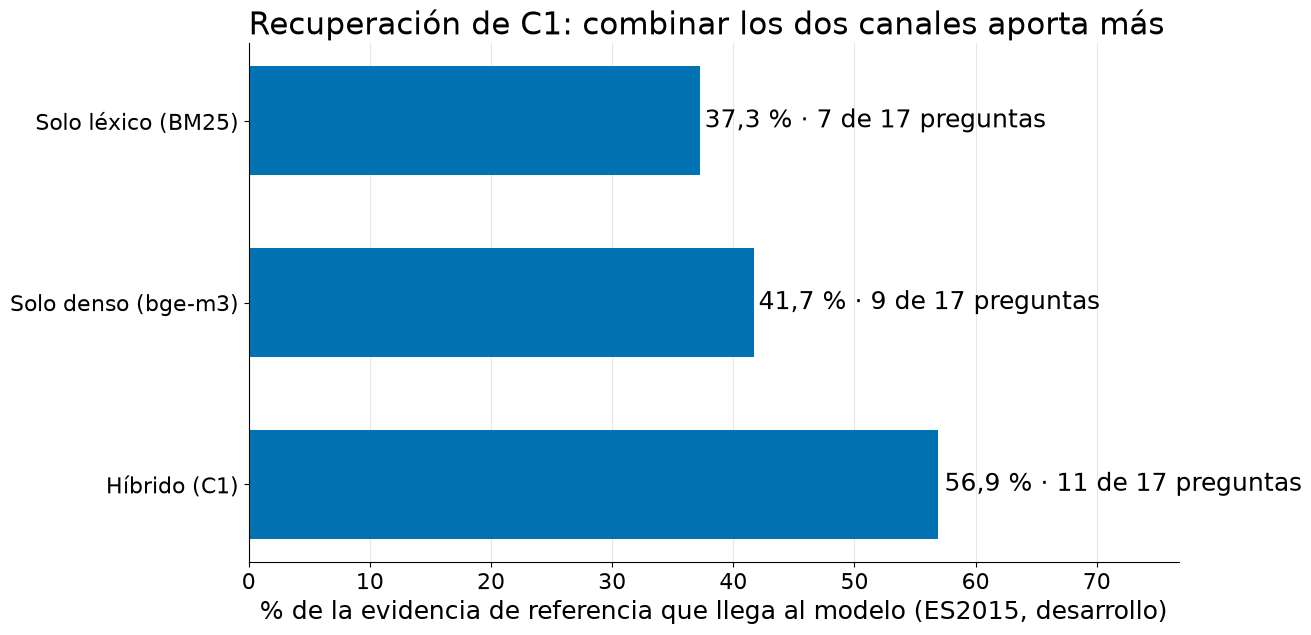

In [26]:
with video_style():
    fig = plot_hbars(
        {MODE_NAMES[m.mode]: m.result.mean_delivered_recall * 100 for m in ABLATION.modes},
        annotations=[
            f"{es(m.result.mean_delivered_recall * 100, 1)} % · "
            f"{questions_with_any_delivered_hit(m.result)} de {ABLATION.n_questions} preguntas"
            for m in ABLATION.modes
        ],
        xlabel="% de la evidencia de referencia que llega al modelo (ES2015, desarrollo)",
        title="Recuperación de C1: combinar los dos canales aporta más",
    )
    EXPORTED.append(save_figure(fig, FIGURES_DIR / "modelos-ablacion-recuperacion.png"))
    display(fig)
    plt.close(fig)

## 6.3 El umbral τ del Experimento A: calibración con un juez y un desvío declarado

**Qué es τ.** Una decisión extraída cuenta como «la misma» que una de la referencia si la
similitud de sus *embeddings* es al menos τ. Con un τ bajo se acepta casi cualquier parecido;
con uno alto, solo textos casi iguales. Como elegir uno solo permitiría escoger el más
favorable, el F1 se informa como **curva** sobre la grilla de τ.

**Método (prerregistrado, notebook 17).** Dos criterios se fijaron antes de mirar resultados:
(A) un **control nulo** (puntuar la salida de un equipo contra la referencia de otro: ningún
acierto puede ser real) y (B) una **muestra de pares juzgada por un modelo** de otra familia
(`gpt-oss:20b`) que responde «¿describen ambos textos la misma decisión?». La regla era
τ = máx(τ nulo, τ juez). El criterio B se puede **recalcular sin Ollama** desde las
respuestas guardadas del juez; el control nulo exige *embeddings* y se cita del ADR 0012.

In [27]:
JUDGMENTS = load_stored_judgments(JudgmentStore(EXPERIMENT_A_DIR / "tau-calibration"))
BINS = bin_table(JUDGMENTS)
TAU_JUEZ = tau_judge(BINS)
BIN_TABLE = pd.DataFrame(
    {
        "intervalo de similitud": [
            f"[{lo:.2f}; {hi:.2f})".replace(".", ",")
            for lo, hi in zip(BINS.bin_low, BINS.bin_high, strict=True)
        ],
        "pares juzgados": BINS["n"],
        "«misma decisión»": BINS["yes"],
        "proporción": BINS["rate"].map(lambda v: es(v, 2)),
        "IC 95 % (Wilson)": [
            f"{es(a, 2)}-{es(b, 2)}" for a, b in zip(BINS.ci_low, BINS.ci_high, strict=True)
        ],
    }
).set_index("intervalo de similitud")
BIN_TABLE

,pares juzgados,«misma decisión»,proporción,IC 95 % (Wilson)
intervalo de similitud,,,,
"[0,50; 0,55)",25,3,"0,12","0,04-0,30"
"[0,55; 0,60)",25,6,"0,24","0,11-0,43"
"[0,60; 0,65)",25,7,"0,28","0,14-0,48"
"[0,65; 0,70)",25,8,"0,32","0,17-0,52"
"[0,70; 0,75)",25,20,"0,80","0,61-0,91"
"[0,75; 0,80)",25,19,"0,76","0,57-0,89"
"[0,80; 0,85)",25,23,"0,92","0,75-0,98"
"[0,85; 0,90)",25,23,"0,92","0,75-0,98"


In [28]:
below, above = BINS[BINS.bin_low < TAU_JUEZ], BINS[BINS.bin_low >= TAU_JUEZ]
md(
    f"**Lectura.** El juez dice «misma decisión» en a lo más {pct(below['rate'].max(), 0)} de los "
    "pares "
    f"por debajo de {es(TAU_JUEZ, 2)} y en al menos {pct(above['rate'].min(), 0)} desde ahí: "
    f"τ del criterio B = **{es(TAU_JUEZ, 2)}**, con {es(len(JUDGMENTS))} pares juzgados. El "
    "control nulo "
    "dio 0,80 (ADR 0012), así que la regla prerregistrada daba 0,80; pero con ese τ casi no queda "
    "cobertura real. **Desvío declarado:** el ADR 0012 fijó **τ principal = 0,70**, con 0,75 y "
    "0,80 como "
    "sensibilidad y la curva completa siempre al lado. La razón no es que 0,70 dé mejores "
    "resultados, "
    "sino un defecto del control nulo: cruza dos equipos con el mismo encargo de diseño (mismo "
    "precio, "
    "mismo costo), así que parte de lo que cuenta como «azar» es la misma decisión de verdad y el "
    "piso "
    "nulo está sobrestimado. El juez complementa la validación manual del protocolo, no la "
    "sustituye, y "
    "su concordancia con una persona sobre 50 pares **sigue pendiente**."
)

**Lectura.** El juez dice «misma decisión» en a lo más 32 % de los pares por debajo de 0,70 y en al menos 76 % desde ahí: τ del criterio B = **0,70**, con 200 pares juzgados. El control nulo dio 0,80 (ADR 0012), así que la regla prerregistrada daba 0,80; pero con ese τ casi no queda cobertura real. **Desvío declarado:** el ADR 0012 fijó **τ principal = 0,70**, con 0,75 y 0,80 como sensibilidad y la curva completa siempre al lado. La razón no es que 0,70 dé mejores resultados, sino un defecto del control nulo: cruza dos equipos con el mismo encargo de diseño (mismo precio, mismo costo), así que parte de lo que cuenta como «azar» es la misma decisión de verdad y el piso nulo está sobrestimado. El juez complementa la validación manual del protocolo, no la sustituye, y su concordancia con una persona sobre 50 pares **sigue pendiente**.

## 6.4 Resumen: qué se fijó, cómo y con qué evidencia

In [29]:
HYPERPARAMETERS = pd.DataFrame(
    [
        (
            "Tamaño de fragmento, turnos compartidos, K (C1)",
            f"{C1P['max_chars']} / {C1P['overlap_turns']} / {C1P['k']}",
            "*Grid search* prerregistrado, 32 configuraciones",
            "Sección 6.1; ADR 0007; notebook 06",
        ),
        (
            "Canales de recuperación (C1)",
            "BM25 + denso, fusión RRF",
            "Ablación de los tres modos",
            "Sección 6.2",
        ),
        ("`rrf_k`", str(RET["rrf_k"]), "Igual al de OpenKOS (no se buscó)", "`[retrieval]`"),
        (
            "Bloques que entrega `openkos query` (C2, C3)",
            str(RET["answer_limit"]),
            "Valor por defecto de OpenKOS, conservado a propósito",
            "ADR 0007, decisión 5",
        ),
        (
            "Modelo generador",
            SB["generative_model"],
            "Fijado por diseño (el mismo en todas las condiciones)",
            "Sección 5.1; ADR 0006",
        ),
        ("Modelo de *embeddings*", SB["embedding_model"], "Heredado de OpenKOS", "Sección 5.1"),
        (
            "Modelo extractor (C2)",
            "qwen3:8b hoy; **pendiente**",
            "*Screen* prerregistrado con reglas de veto",
            "Sección 5.3; #143",
        ),
        (
            "Modelo juez",
            CFG["judge"]["model"],
            "Umbrales prerregistrados sobre 42 ítems",
            "Sección 5.4; notebook 05",
        ),
        (
            "`temperature`, semilla, ventana",
            f"{es(SB['temperature'], 1)}, {SB['seed']}, {es(SB['context_window_tokens'])} tokens",
            "Fijados por diseño; **no se exploró** su sensibilidad",
            "Sección 11",
        ),
        (
            "`top_p`",
            es(SB["top_p"], 1),
            "Configurado; C1 no lo envía (OpenKOS tampoco)",
            "`[shared_budget]`",
        ),
        (
            "*Prompts* de respuesta",
            "Copia byte a byte de OpenKOS, con huella SHA-256",
            "**No se buscan a propósito**",
            "ADR 0006",
        ),
        (
            "Umbral τ (Experimento A)",
            "0,70 (principal); 0,75 y 0,80 de sensibilidad",
            "Calibración con control nulo y juez; desvío declarado",
            "Sección 6.3; ADR 0012",
        ),
        (
            "Criterio de éxito",
            "D16/D17: diferencia pareada en E3",
            "Simulación de potencia",
            "Sección 1.2; ADR 0010",
        ),
    ],
    columns=["parámetro", "valor", "método", "dónde está la evidencia"],
).set_index("parámetro")
HYPERPARAMETERS

,valor,método,dónde está la evidencia
parámetro,,,
"Tamaño de fragmento, turnos compartidos, K (C1)",1200 / 1 / 5,"*Grid search* prerregistrado, 32 configuraciones",Sección 6.1; ADR 0007; notebook 06
Canales de recuperación (C1),"BM25 + denso, fusión RRF",Ablación de los tres modos,Sección 6.2
`rrf_k`,60,Igual al de OpenKOS (no se buscó),`[retrieval]`
"Bloques que entrega `openkos query` (C2, C3)",5,"Valor por defecto de OpenKOS, conservado a propósito","ADR 0007, decisión 5"
Modelo generador,qwen3:8b,Fijado por diseño (el mismo en todas las condiciones),Sección 5.1; ADR 0006
Modelo de *embeddings*,bge-m3,Heredado de OpenKOS,Sección 5.1
Modelo extractor (C2),qwen3:8b hoy; **pendiente**,*Screen* prerregistrado con reglas de veto,Sección 5.3; #143
Modelo juez,gpt-oss:20b,Umbrales prerregistrados sobre 42 ítems,Sección 5.4; notebook 05
"`temperature`, semilla, ventana","0,1, 42, 12.288 tokens",Fijados por diseño; **no se exploró** su sensibilidad,Sección 11


**Lectura.** Cuatro métodos distintos, cada uno con el rigor que el parámetro pide: *grid
search* donde hay una grilla y una métrica barata (C1), tamizaje con reglas de veto donde
cada corrida es cara y la ganancia de un modelo puede ser solo ruido (extractor), umbrales
prerregistrados donde un modelo debe cumplir requisitos mínimos (juez) y ablación donde la
pregunta es si una pieza se justifica (recuperación). Lo que **no** se buscó (temperatura,
semilla, ventana, `top_p`, *prompts*) se fijó por diseño para mantener las condiciones iguales,
y eso es una decisión, no un olvido.

---

# 7. Línea base y primeros resultados (desarrollo)

**Qué se hace y por qué.** El curso pide comparar **siempre** contra una línea base simple. Aquí
hay dos: **C1**, el RAG documental ajustado con honestidad, que es la práctica que cualquier
organización tendría hoy; y **C0**, un diagnóstico todavía más simple: el mismo modelo
generador respondiendo **sin ningún texto de apoyo**. C0 no es una condición de la tesis (no
se puede ejecutar sobre evaluación) y sirve para dos cosas: dar el piso más simple posible y
medir si el modelo ya conoce el escenario de AMI, lo que contaminaría la comparación.

Las corridas son de **desarrollo y de humo**: el motor del Experimento B funciona de punta a
punta con modelos reales, pero con 21 preguntas de calibración de ES2015. **Ninguna cifra de
esta sección es un resultado de la tesis** (ADR 0005).

## 7.1 Qué corridas se usan

In [30]:
MANIFESTS = {}
for path in B_RUNS.values():
    manifest = json.loads((path / MANIFEST_FILE).read_text(encoding="utf-8"))
    MANIFESTS[manifest["run_name"]] = manifest
PROV = manifest_provenance_table(MANIFESTS)
PROV["preguntas"] = [m["counts"]["questions"] for m in MANIFESTS.values()]
PROV["git_dirty"] = PROV["git_dirty"].map({True: "sí", False: "no"}).fillna("no registrado")
PROV.set_index("run")[
    [
        "conditions",
        "preguntas",
        "runs",
        "generative_model",
        "generative_digest",
        "judge_digest",
        "commit",
        "git_dirty",
    ]
].rename(
    columns={
        "conditions": "condición",
        "runs": "corridas",
        "generative_model": "modelo generador",
        "generative_digest": "huella del generador",
        "judge_digest": "huella del juez",
        "git_dirty": "árbol sin confirmar",
    }
)

,condición,preguntas,corridas,modelo generador,huella del generador,huella del juez,commit,árbol sin confirmar
run,,,,,,,,
diagnostico-sin-contexto-es2015,C0,21,3,qwen3:8b,500a1f067a9f,f38aa0c53da5,c9a632ba,sí
humo-c1-es2015,C1,21,1,qwen3:8b,—,—,0e1809a1,no registrado
humo-c2-es2015-conceptos,C2,21,1,qwen3:8b,500a1f067a9f,f38aa0c53da5,0db4d021,no


**Lectura.** Las tres corridas usan el mismo generador, el mismo juez y las mismas 21
preguntas, pero **C0 se corrió 3 veces y C1 y C2 una sola**: se comparan porcentajes, no
conteos absolutos, y eso se tiene presente al leer. La corrida de C1 es previa al registro de
huellas de modelo (su manifiesto no las trae), y la de C0 se hizo con el árbol de trabajo sin
confirmar; ambas cosas se declaran y no cambian las cifras.

## 7.2 Resultado por estrato

In [31]:
SUMMARY = {
    name: {s.stratum: s for s in stratum_summary(records)} for name, records in RECORDS.items()
}
STRATA = ["E1", "E2", "E3", "E4"]
STRATUM_NAMES = {
    "E1": "E1 hecho puntual",
    "E2": "E2 estado vigente",
    "E3": "E3 evolución",
    "E4": "E4 sin respuesta",
}
rows = []
for stratum in STRATA:
    row = {"estrato": STRATUM_NAMES[stratum]}
    for name in B_RUNS:
        s = SUMMARY[name][stratum]
        row[name] = f"{s.correct} de {s.n} ({es(s.correct_rate * 100, 1)} %)"
    rows.append(row)
TOTALS = {
    name: (sum(s.correct for s in per.values()), sum(s.n for s in per.values()))
    for name, per in SUMMARY.items()
}
rows.append(
    {
        "estrato": "Todas",
        **{n: f"{c} de {t} ({es(c / t * 100, 1)} %)" for n, (c, t) in TOTALS.items()},
    }
)
BY_STRATUM = pd.DataFrame(rows).set_index("estrato")
BY_STRATUM.columns = [
    "C0 sin contexto (3 corridas)",
    "C1 RAG (1 corrida)",
    "C2 base compilada (1 corrida)",
]
BY_STRATUM

,C0 sin contexto (3 corridas),C1 RAG (1 corrida),C2 base compilada (1 corrida)
estrato,,,
E1 hecho puntual,"8 de 42 (19,0 %)","10 de 14 (71,4 %)","5 de 14 (35,7 %)"
E2 estado vigente,"0 de 6 (0,0 %)","2 de 2 (100,0 %)","1 de 2 (50,0 %)"
E3 evolución,"0 de 3 (0,0 %)","0 de 1 (0,0 %)","0 de 1 (0,0 %)"
E4 sin respuesta,"6 de 12 (50,0 %)","4 de 4 (100,0 %)","4 de 4 (100,0 %)"
Todas,"14 de 63 (22,2 %)","16 de 21 (76,2 %)","10 de 21 (47,6 %)"


In [32]:
md(
    f"**Lectura.** En el conjunto de desarrollo, sin contexto el modelo acierta "
    f"{pct(TOTALS['C0'][0] / TOTALS['C0'][1])} de las respuestas; con la recuperación de C1 sube a "
    f"{pct(TOTALS['C1'][0] / TOTALS['C1'][1])}; y la base compilada de C2 queda en "
    f"{pct(TOTALS['C2'][0] / TOTALS['C2'][1])}. **Recuperar texto aporta mucho** (la diferencia "
    "entre C0 y C1 "
    "es lo que la recuperación suma), y **en esta primera corrida C2 está por debajo de la línea "
    "base**, "
    f"sobre todo en E1: {SUMMARY['C2']['E1'].correct} de {SUMMARY['C2']['E1'].n} frente a "
    f"{SUMMARY['C1']['E1'].correct} de {SUMMARY['C1']['E1'].n} de C1. La hipótesis H1 esperaba "
    "paridad en E1; "
    "la propuesta pide explicar una pérdida ahí como una **regresión** (notebook 16). Hay un solo "
    "caso de evolución (E3) en el conjunto: no se puede decir nada sobre lo que la tesis quiere "
    "probar. "
    "Son 21 preguntas y una corrida: la dirección es clara, la magnitud no. En E4, C0 "
    f"«acierta» {SUMMARY['C0']['E4'].correct} de {SUMMARY['C0']['E4'].n} porque el juez acepta "
    "como "
    "correcta una respuesta que admite no saber; no mide abstención en sentido estricto."
)

**Lectura.** En el conjunto de desarrollo, sin contexto el modelo acierta 22,2 % de las respuestas; con la recuperación de C1 sube a 76,2 %; y la base compilada de C2 queda en 47,6 %. **Recuperar texto aporta mucho** (la diferencia entre C0 y C1 es lo que la recuperación suma), y **en esta primera corrida C2 está por debajo de la línea base**, sobre todo en E1: 5 de 14 frente a 10 de 14 de C1. La hipótesis H1 esperaba paridad en E1; la propuesta pide explicar una pérdida ahí como una **regresión** (notebook 16). Hay un solo caso de evolución (E3) en el conjunto: no se puede decir nada sobre lo que la tesis quiere probar. Son 21 preguntas y una corrida: la dirección es clara, la magnitud no. En E4, C0 «acierta» 6 de 12 porque el juez acepta como correcta una respuesta que admite no saber; no mide abstención en sentido estricto.

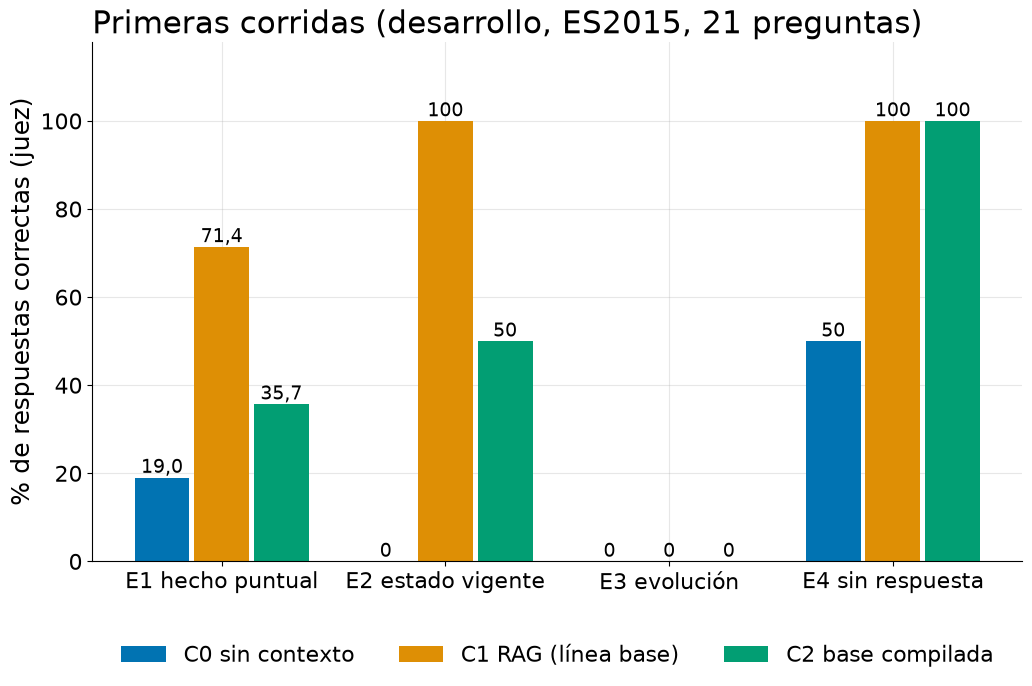

In [33]:
with video_style():
    fig = plot_grouped_bars(
        [STRATUM_NAMES[s] for s in STRATA],
        {
            "C0 sin contexto": [SUMMARY["C0"][s].correct_rate * 100 for s in STRATA],
            "C1 RAG (línea base)": [SUMMARY["C1"][s].correct_rate * 100 for s in STRATA],
            "C2 base compilada": [SUMMARY["C2"][s].correct_rate * 100 for s in STRATA],
        },
        ylabel="% de respuestas correctas (juez)",
        title="Primeras corridas (desarrollo, ES2015, 21 preguntas)",
        ylim=(0, 118),
    )
    EXPORTED.append(save_figure(fig, FIGURES_DIR / "modelos-baseline-por-estrato.png"))
    display(fig)
    plt.close(fig)

## 7.3 Cómo fallan: respuestas equivocadas y abstenciones

Que una respuesta sea incorrecta puede significar dos cosas distintas (sección 1.3): el sistema
**contestó algo falso** o **se abstuvo** diciendo que no encontró información. La tabla las
separa en C1 y C2 (C0 no se abstiene con una marca, así que no se puede dividir).

In [34]:
FAIL_ROWS = []
for name in ("C1", "C2"):
    for f in failure_split(RECORDS[name]):
        FAIL_ROWS.append(
            {
                "condición": name,
                "estrato": STRATUM_NAMES[f.stratum],
                "preguntas": f.n,
                "correctas": f.correct,
                "respuesta incorrecta": f.wrong_answer,
                "abstención incorrecta": f.abstained_wrong,
                "abstención correcta (E4)": f.abstained_right,
            }
        )
FAILS = pd.DataFrame(FAIL_ROWS).set_index(["condición", "estrato"])
CAUSES = {name: abstention_causes(RECORDS[name]) for name in ("C1", "C2")}
FAILS

preguntas  correctas  respuesta incorrecta  abstención incorrecta  abstención correcta (E4)
condición estrato                                                                                                       
C1        E1 hecho puntual          14         10                     1                      3                         0
          E2 estado vigente          2          2                     0                      0                         0
          E3 evolución               1          0                     0                      1                         0
          E4 sin respuesta           4          4                     0                      0                         4
C2        E1 hecho puntual          14          5                     5                      4                         0
          E2 estado vigente          2          1                     0                      1                         0
          E3 evolución               1          0                     0                      1                         0
          E4 sin respuesta           4          4                     0                      0                         4

In [35]:
f1, f2 = (
    {f.stratum: f for f in failure_split(RECORDS["C1"])},
    {f.stratum: f for f in failure_split(RECORDS["C2"])},
)
md(
    f"**Lectura.** En E1, C1 falla {f1['E1'].n - f1['E1'].correct} veces, y "
    f"{f1['E1'].abstained_wrong} de ellas son "
    f"abstenciones; C2 falla {f2['E1'].n - f2['E1'].correct}, de las cuales "
    f"{f2['E1'].wrong_answer} son respuestas "
    f"falsas y {f2['E1'].abstained_wrong} abstenciones. Es decir, la pérdida de C2 viene sobre "
    "todo de "
    "**contestar algo equivocado**, no de callar. **Dato importante para el diseño:** en estas "
    "corridas "
    f"las {CAUSES['C1'].n_abstained} abstenciones de C1 y las {CAUSES['C2'].n_abstained} de C2 "
    "las decidió la "
    f"**verificación de suficiencia** ({CAUSES['C1'].refused_by_sufficiency} y "
    f"{CAUSES['C2'].refused_by_sufficiency} "
    "respectivamente), no la redacción de la respuesta. Por eso el modelo que hace esa "
    "verificación "
    "importa tanto para la igualdad entre condiciones (sección 5.6)."
)

**Lectura.** En E1, C1 falla 4 veces, y 3 de ellas son abstenciones; C2 falla 9, de las cuales 5 son respuestas falsas y 4 abstenciones. Es decir, la pérdida de C2 viene sobre todo de **contestar algo equivocado**, no de callar. **Dato importante para el diseño:** en estas corridas las 8 abstenciones de C1 y las 10 de C2 las decidió la **verificación de suficiencia** (8 y 10 respectivamente), no la redacción de la respuesta. Por eso el modelo que hace esa verificación importa tanto para la igualdad entre condiciones (sección 5.6).

## 7.4 El diagnóstico sin contexto (C0): ¿qué aporta recuperar y hay contaminación?

C0 permite descartar una explicación incómoda: que el modelo ya «se sepa» las reuniones de AMI
(un corpus público que pudo haber estado en su entrenamiento). Si fuera así, acertaría sin
contexto datos que solo están en la reunión, como el precio de venta o el costo máximo.
La tabla pone, por pregunta de E1, cuántas de las 3 corridas de C0 acertó, junto al resultado
de C1 y C2. Como ES2015 es de desarrollo, se pueden leer las preguntas.

In [36]:
def correct_by_question(records):
    out = {}
    for r in records:
        out.setdefault(r["question_id"], []).append(
            bool(r["verdict"]["correct"]) if r.get("verdict") else None
        )
    return out


C0_BY_Q = correct_by_question(RECORDS["C0"])
C1_BY_Q = correct_by_question(RECORDS["C1"])
C2_BY_Q = correct_by_question(RECORDS["C2"])
E1_IDS = sorted(q for q, qq in QUESTIONS.items() if qq.stratum.value.startswith("E1"))
E1_TABLE = pd.DataFrame(
    [
        {
            "pregunta": q.split(".")[-1],
            "texto": QUESTIONS[q].text,
            "C0 (de 3 corridas)": f"{sum(C0_BY_Q[q])} de {len(C0_BY_Q[q])}",
            "C1": "sí" if C1_BY_Q[q][0] else "no",
            "C2": "sí" if C2_BY_Q[q][0] else "no",
        }
        for q in E1_IDS
    ]
).set_index("pregunta")
E1_TABLE

,texto,C0 (de 3 corridas),C1,C2
pregunta,,,,
q002,What selling price was set for the remote control?,0 de 3,sí,no
q003,Which market was the remote control intended for?,0 de 3,sí,no
q004,What was the maximum allowed production cost per remote control?,0 de 3,sí,no
q006,Which feature did management decide to leave out because it was considered outdated?,0 de 3,sí,no
q007,Which company branding elements had to be incorporated into the remote control?,2 de 3,sí,sí
q008,Was an LCD included in the remote control design?,3 de 3,no,sí
q010,What feature did the team approve to help find a misplaced remote control?,0 de 3,sí,sí
q011,What lighting feature did the team decide to incorporate into the remote control buttons?,0 de 3,no,no
q013,What type of user interface was chosen for the remote control?,0 de 3,sí,sí


In [37]:
never = [q.split(".")[-1] for q in E1_IDS if sum(C0_BY_Q[q]) == 0]
hits = [q.split(".")[-1] for q in E1_IDS if sum(C0_BY_Q[q]) > 0]
PRICE, COST = "ES2015.q002", "ES2015.q004"
mixed = [q for q, v in C0_BY_Q.items() if len(set(v)) > 1]
md(
    f"**Lectura.** De las {len(E1_IDS)} preguntas de E1, C0 no acierta ninguna de sus 3 corridas "
    "en "
    f"{len(never)} y acierta alguna en {len(hits)} ({', '.join(hits)}). Las dos preguntas que más "
    "delatarían una "
    "memorización del corpus, el precio de venta "
    f"({QUESTIONS[PRICE].reference_answer.rstrip('.')}) y el costo máximo "
    f"({QUESTIONS[COST].reference_answer.rstrip('.')}), fallan en las 3 corridas "
    f"({sum(C0_BY_Q[PRICE])} de 3 y {sum(C0_BY_Q[COST])} de 3). **No hay indicio de contaminación "
    "con AMI.** "
    "Los aciertos de C0 se leen como conocimiento general (qué funciones tiene un control "
    "remoto), no como "
    "memoria de la reunión, según la revisión humana registrada en el mensaje de *commit* del PR "
    "#175 "
    "(«los aciertos E1 (q007, q008, q020) son conocimiento general sobre controles remotos»). "
    f"Solo {len(mixed)} de las {len(C0_BY_Q)} preguntas cambió de veredicto entre corridas."
)

**Lectura.** De las 14 preguntas de E1, C0 no acierta ninguna de sus 3 corridas en 11 y acierta alguna en 3 (q007, q008, q020). Las dos preguntas que más delatarían una memorización del corpus, el precio de venta (Twenty-five Euros) y el costo máximo (Twelve Euros and fifty cents), fallan en las 3 corridas (0 de 3 y 0 de 3). **No hay indicio de contaminación con AMI.** Los aciertos de C0 se leen como conocimiento general (qué funciones tiene un control remoto), no como memoria de la reunión, según la revisión humana registrada en el mensaje de *commit* del PR #175 («los aciertos E1 (q007, q008, q020) son conocimiento general sobre controles remotos»). Solo 1 de las 21 preguntas cambió de veredicto entre corridas.

In [38]:
LENIENT = pd.DataFrame(
    [
        {
            "pregunta": q.split(".")[-1],
            "referencia": QUESTIONS[q].reference_answer,
            "respuesta de C0 (inicio)": next(
                r for r in RECORDS["C0"] if r["question_id"] == q and r["run"] == 0
            )["answer"]["text"][:210]
            + "…",
            "veredicto": next(r for r in RECORDS["C0"] if r["question_id"] == q and r["run"] == 0)[
                "verdict"
            ]["correct"],
        }
        for q in ("ES2015.q008", "ES2015.q020")
    ]
).set_index("pregunta")
LENIENT

,referencia,respuesta de C0 (inicio),veredicto
pregunta,,,
q008,"No, an LCD was excluded.",The inclusion of an LCD (liquid crystal display) in a remote control design is not typical. Remote controls generall...,True
q020,"Power, channel selection, and volume control.","A remote control typically provides several basic functions, depending on the device it is used for. Common function...",True


**Lectura.** Son los dos aciertos más claros de C0 (3 de 3 corridas). La pregunta q020 pide las funciones
básicas de un control remoto: cualquier modelo las conoce. La q008 pregunta si se incluyó una
pantalla LCD; la referencia es «no, se excluyó», y la respuesta de C0 **no afirma eso**: dice que
incluir una LCD «no es típico» y habla de tecnologías de pantalla en general. Aun así el juez la
marcó correcta, con un razonamiento que atribuye a la respuesta algo que no dice. Es una
**limitación del juez**: puede ser indulgente con una respuesta genérica que coincide con el
sentido de la referencia sin comprometerse. Importa por dos motivos: infla el piso de C0 un poco, y
obliga a la verificación humana del 20 % de las respuestas (sección 10) a mirar justo este tipo de
caso.

## 7.5 La pérdida de C2 en E1 y su atribución (OE4)

La pérdida de C2 en E1 es el hallazgo más fuerte de las corridas de humo, y la propuesta pide
tratarla como una regresión por explicar. El notebook 16 miró **qué texto recuperó C2** para
cada pregunta y dejó una hoja para que una persona clasificara cada falla según la etapa donde
nació (jss, PR #177): extracción (el hecho no quedó bien en la base), recuperación (estaba y no se recuperó) o
síntesis (se recuperó y la respuesta lo contradice).

In [39]:
OE4_ROWS = read_worksheet_rows(B_RUNS["C2"] / "oe4-etapa-e1.csv")
n_oe4 = len(OE4_ROWS)
n_oe4_labelled = sum(1 for r in OE4_ROWS if r["etapa_humana"].strip())
OE4_E1 = [r for r in context_rows(RECORDS["C2"], RECORDS["C1"], QUESTIONS) if r.stratum == "E1"]
OE4_RULE = [
    "sintesis" for e in error_evidence(OE4_E1, RECORDS["C2"], QUESTIONS) if e.rule_stage is not None
]
OE4_STAGES = count_stages(OE4_RULE, OE4_ROWS)
n_oe4_total = sum(OE4_STAGES.values())
md(
    f"**Estado.** De las {n_oe4_total} fallas E1 de C2, {len(OE4_RULE)} se atribuye por regla "
    f"(síntesis) y {n_oe4} necesitaban una persona; jss etiquetó las {n_oe4_labelled} (PR #177, "
    "`CONTRIBUTING.md` §7.6). El reparto, con las dos fuentes juntas: "
    f"**recuperación {OE4_STAGES['recuperacion']}**, **extracción {OE4_STAGES['extraccion']}** y "
    f"**síntesis {OE4_STAGES['sintesis']}**. Son datos de desarrollo, de una sola serie y de una "
    "sola persona: una dirección, no un resultado de la tesis."
)

**Estado.** De las 9 fallas E1 de C2, 1 se atribuye por regla (síntesis) y 8 necesitaban una persona; jss etiquetó las 8 (PR #177, `CONTRIBUTING.md` §7.6). El reparto, con las dos fuentes juntas: **recuperación 4**, **extracción 3** y **síntesis 2**. Son datos de desarrollo, de una sola serie y de una sola persona: una dirección, no un resultado de la tesis.

Las mismas cifras, en un gráfico. El notebook 20 las lee junto con la tabla de preguntas E1 de
C1 y C2.

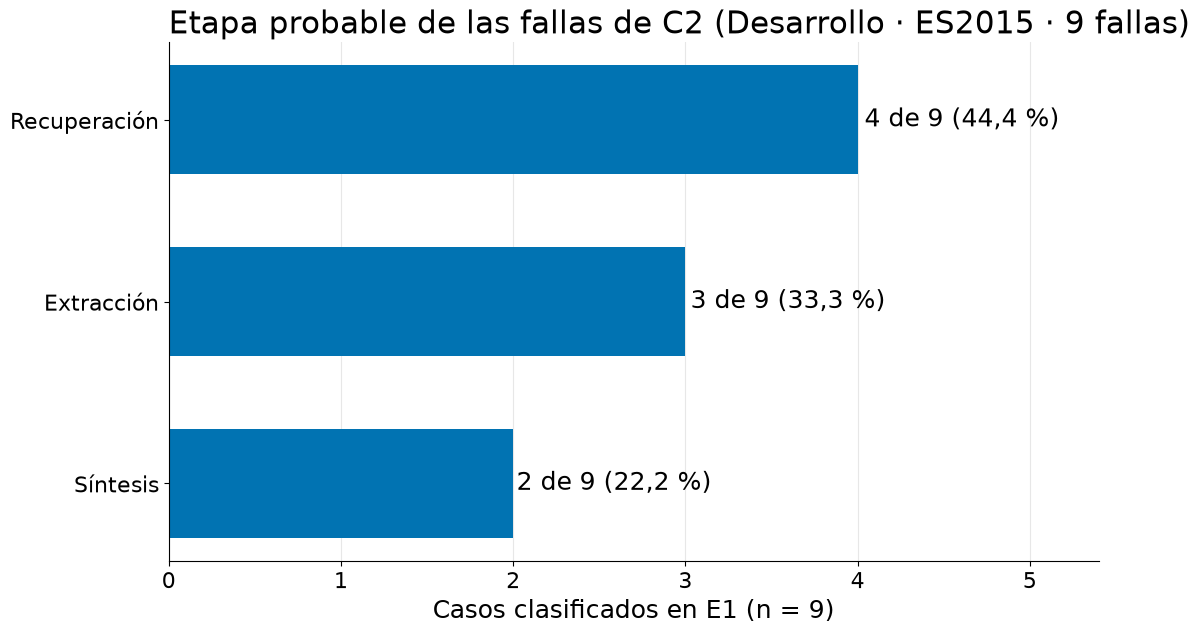

In [40]:
OE4_NAMES = {"recuperacion": "Recuperación", "extraccion": "Extracción", "sintesis": "Síntesis"}
OE4_SHARES = stage_shares({stage: OE4_STAGES[stage] for stage in OE4_NAMES})
with video_style():
    fig = plot_hbars(
        {OE4_NAMES[s]: float(OE4_SHARES.loc[s, "cases"]) for s in OE4_SHARES.index},
        annotations=[
            f"{n} de {n_oe4_total} ({pct(share)})"
            for n, share in zip(OE4_SHARES["cases"], OE4_SHARES["share"], strict=True)
        ],
        xlabel=f"Casos clasificados en E1 (n = {n_oe4_total})",
        title="Etapa probable de las fallas de C2 (Desarrollo · ES2015 · 9 fallas)",
    )
    EXPORTED.append(save_figure(fig, FIGURES_DIR / "modelos-etapas-fallas-c2.png"))
    display(fig)
    plt.close(fig)

**Lectura.** Pesa más la **recuperación** que la síntesis: en cuatro fallas el hecho estaba en la
base y no llegó al modelo, y a menudo llegó la decisión vecina del mismo tramo de la reunión (por
ejemplo, la de DVD y VCR en lugar de la exclusión del teletexto). Tres fallas son de **extracción**
(la base guardó un valor cercano o un detalle a medias) y dos de **síntesis**. Otros dos hallazgos
de las notas: los resúmenes de tema llegan **recortados** y pierden el dato clave, y una propuesta
descartada que la extracción guardó como decisión **contaminó** la memoria y engañó al modelo en
una pregunta. Además, el juez resultó **estricto con una respuesta parcial** (en `q023` marcó
incorrecta una respuesta correcta en lo sustancial: un falso negativo), lo que se suma a su
indulgencia con la respuesta genérica de la sección 7.4.


---

# 8. Variabilidad, reproducibilidad y costo

**Qué se hace y por qué.** Como no hay entrenamiento no hay validación cruzada, pero sí hay dos
fuentes de variación que el diseño controla: el azar al redactar (se fija con semilla y se
mide repitiendo) y el conjunto de preguntas (se mide con *bootstrap*). Y como una corrida solo se
puede repetir si se sabe exactamente con qué se hizo, cada corrida guarda la huella de sus modelos.

## 8.1 Semilla y repetición

In [41]:
seed_pairs = pairwise_overlap(ES2015_RUNS)
r1 = next(r for r in ES2015_RUNS if r.run_name == "es2015-explora-r1")
r3x0 = next(r for r in ES2015_RUNS if r.run_name == "es2015-explora-r3x" and r.run == 0)
SAME_SEED = reproducibility_check(r1, r3x0)
different = seed_pairs[
    seed_pairs["run_a"].str.startswith("es2015-explora-r3x")
    & seed_pairs["run_b"].str.startswith("es2015-explora-r3x")
]
md(
    f"**Lectura.** Cada configuración se corre **{SB['runs_per_config']} veces** con semillas "
    f"{SB['seed']}, {SB['seed'] + 1} y {SB['seed'] + 2} (la base más el número de corrida), y se "
    "informa media y "
    f"dispersión. Con la **misma semilla** ({SAME_SEED.seed}), dos extracciones de ES2015 con "
    "OpenKOS son "
    f"idénticas decisión por decisión ({'sí' if SAME_SEED.identical else 'NO'}: "
    f"{SAME_SEED.n_decisions[0]} decisiones en cada una). "
    "Con **semillas distintas** las corridas comparten un núcleo estable, pero entre una cuarta "
    "parte y un "
    f"tercio de lo extraído cambia: el índice de Jaccard entre pares de corridas va de "
    f"{es(different['jaccard'].min(), 2)} a {es(different['jaccard'].max(), 2)}. Esa variación es "
    "la razón de "
    "repetir; la semilla fija el azar, no lo elimina. En las preguntas de C0 (3 corridas), "
    f"{len(mixed)} de {len(C0_BY_Q)} cambió de veredicto entre corridas."
)

**Lectura.** Cada configuración se corre **3 veces** con semillas 42, 43 y 44 (la base más el número de corrida), y se informa media y dispersión. Con la **misma semilla** (42), dos extracciones de ES2015 con OpenKOS son idénticas decisión por decisión (sí: 71 decisiones en cada una). Con **semillas distintas** las corridas comparten un núcleo estable, pero entre una cuarta parte y un tercio de lo extraído cambia: el índice de Jaccard entre pares de corridas va de 0,70 a 0,82. Esa variación es la razón de repetir; la semilla fija el azar, no lo elimina. En las preguntas de C0 (3 corridas), 1 de 21 cambió de veredicto entre corridas.

## 8.2 Procedencia: con qué se corrió cada cosa

In [42]:
PROV_EXTRACTION = provenance_table(ES2015_RUNS).T
PROV_EXTRACTION

,es2015-explora-r1,es2015-explora-r3x
versión de OpenKOS,0.5.5,0.5.5
modelo generativo,qwen3:8b,qwen3:8b
digest del modelo generativo,500a1f067a9f,500a1f067a9f
modelo de embeddings,bge-m3,bge-m3
digest del modelo de embeddings,790764642607,790764642607
temperatura,0.1,0.1
semilla base,42,42
corridas,1,3
commit,9d4687d528f0931eb37310807a9c839fbafb81a9,9d4687d528f0931eb37310807a9c839fbafb81a9
duración (min),25.7,75.0


**Lectura.** Cada carpeta de extracción deja la versión de OpenKOS, los dos modelos con su
huella digital en Ollama (la identidad exacta de los pesos, no solo la etiqueta), la
temperatura, la semilla y el *commit* del repositorio. Las corridas del Experimento B guardan lo
mismo (sección 7.1). Es lo que permite decir, para cada cifra de este notebook, con qué se produjo.

## 8.3 Costo y latencia por modelo y por rol

In [43]:
SRC_B = "reports/experiment-b/"
SRC_SCREEN = "reports/experiment-a/model-screen-openkos/"
COST_ROWS = []
for name, label in (
    ("C0", "diagnóstico sin contexto (3 corridas)"),
    ("C1", "corrida de humo"),
    ("C2", "corrida de humo"),
):
    COST_ROWS += answer_and_judge_costs(RECORDS[name], label=f"{name} {label}", source=SRC_B)
COST_ROWS += judge_calibration_costs(JUDGE, source="reports/judge-calibration/")
COST_ROWS.append(
    tau_judge_cost(
        json.loads((EXPERIMENT_A_DIR / "tau-calibration" / "run.json").read_text(encoding="utf-8")),
        source="reports/experiment-a/tau-calibration/",
    )
)
COST_ROWS += screen_costs(
    SCREEN_SCORED, phase="screen (5 corridas)", baseline=BASELINE, source=SRC_SCREEN
)
COST_ROWS += screen_costs(
    CONFIRM_SCORED, phase="confirmatoria (15)", baseline=BASELINE, source=SRC_SCREEN
)
for folder in ("es2015-explora-r1", "es2015-explora-r3x"):
    manifest = json.loads((EXPERIMENT_A_DIR / folder / "manifest.json").read_text(encoding="utf-8"))
    COST_ROWS.append(
        extraction_manifest_cost(manifest, label=folder, source="reports/experiment-a/")
    )
COST = cost_frame(COST_ROWS)
ROLE_ES = {"answer": "responder", "judge": "juzgar", "extraction": "extraer"}
COST_SHOWN = pd.DataFrame(
    {
        "rol": COST["role"].map(ROLE_ES),
        "modelo": COST["model"],
        "actividad": COST["activity"],
        "unidades": COST["units"],
        "segundos por unidad": COST["mean_seconds"].map(lambda v: es(v, 1)),
        "total (min)": (COST["total_seconds"] / 60).map(lambda v: es(v, 1)),
        "x el tiempo del 8b": COST["ratio"].map(lambda v: "" if pd.isna(v) else es(v, 1)),
        "detalle": COST["detail"],
    }
).set_index(["rol", "modelo", "actividad"])
COST_SHOWN

unidades segundos por unidad total (min) x el tiempo del 8b  \
rol       modelo                actividad                                                                                                    
responder qwen3:8b              C0 diagnóstico sin contexto (3 corridas) / C0        63                14,9        15,6                      
juzgar    gpt-oss:20b           C0 diagnóstico sin contexto (3 corridas)             63                22,2        23,3                      
responder qwen3:8b              C1 corrida de humo / C1                              21                 8,8         3,1                      
juzgar    gpt-oss:20b           C1 corrida de humo                                   21                 4,2         1,5                      
responder qwen3:8b              C2 corrida de humo / C2                              21                10,3         3,6                      
juzgar    gpt-oss:20b           C2 corrida de humo                                   21                 4,3         1,5                      
          mistral-small3.2:24b  calibración (42 ítems)                              270                 5,5        24,7                      
          atla/selene-mini:q8_0 calibración (42 ítems)                              270                 3,0        13,5                      
          gpt-oss:20b           calibración (42 ítems)                              270                 3,2        14,5                      
                                juicio de pares para τ                              200                 5,4        18,0                      
extraer   qwen3.6:27b           screen (5 corridas) ES2015                            5               580,8        48,4                3,5   
                                screen (5 corridas) TS3009                            5               882,6        73,6                3,3   
          qwen3.6:35b-a3b       screen (5 corridas) ES2015                            5                89,6         7,5                0,5   
                                screen (5 corridas) TS3009                            5               187,1        15,6                0,7   
          qwen3:14b             screen (5 corridas) ES2015                            5               215,9        18,0                1,3   
                                screen (5 corridas) TS3009                            5               222,5        18,5                0,8   
          qwen3:8b              screen (5 corridas) ES2015                            5               167,5        14,0                1,0   
                                screen (5 corridas) TS3009                            5               268,2        22,3                1,0   
          qwen3.6:27b           confirmatoria (15) ES2015                            15               597,6       149,4                3,6   
                                confirmatoria (15) TS3009                            15               894,7       223,7                1,8   
          qwen3:8b              confirmatoria (15) ES2015                            15               165,7        41,4                1,0   
                                confirmatoria (15) TS3009                            15               488,8       122,2                1,0   
                                OpenKOS completo ES2015 (es2015-explora-r1)           1             1.541,6        25,7                      
                                OpenKOS completo ES2015 (es2015-explora-r3x)          3             1.499,4        75,0                      

                                                                                                               detalle  
rol       modelo                actividad                                                                               
responder qwen3:8b              C0 diagnóstico sin contexto (3 corridas) / C0                                           
juzgar    gpt-oss:20b  

In [44]:
answer_c1 = next(r for r in COST_ROWS if r.role == "answer" and "C1" in r.activity)
judge_c1 = next(r for r in COST_ROWS if r.role == "judge" and r.activity.startswith("C1"))
judge_c0 = next(r for r in COST_ROWS if r.role == "judge" and r.activity.startswith("C0"))
full_run = next(r for r in COST_ROWS if r.activity.endswith("(es2015-explora-r3x)"))
ext = screen_by_model(Q_SCREEN).reindex(MODEL_ORDER)["seconds_per_run"]
n_eval = len(CORPUS["evaluation_series"])
n_runs = SB["runs_per_config"]
hours = {m: n_eval * n_runs * ext[m] / 3600 for m in MODEL_ORDER}
md(
    f"**Lectura.** Con `{answer_c1.model}`, responder una pregunta tarda unos "
    f"{es(answer_c1.mean_seconds, 0)} s y "
    f"juzgarla con `{judge_c1.model}` unos {es(judge_c1.mean_seconds, 0)} s: el costo del "
    "Experimento B es pequeño frente "
    f"al de **extraer**. Extraer una serie de cuatro reuniones tarda entre {es(ext.min(), 0)} s "
    f"(`{ext.idxmin()}`) y "
    f"{es(ext.max(), 0)} s (`{ext.idxmax()}`) en el *screen*. Como proyección aritmética (no "
    "medición; el tiempo "
    f"real depende de la carga del equipo), extraer las {n_eval} series de evaluación {n_runs} "
    "veces serían unas "
    f"{es(hours['qwen3:8b'], 1)} h con `qwen3:8b`, {es(hours['qwen3:14b'], 1)} h con `qwen3:14b` y "
    f"{es(hours['qwen3.6:27b'], 1)} h con `qwen3.6:27b`. Ese es el costo del que depende la "
    "decisión del extractor "
    "(#143). **Ojo:** esos tiempos son solo del paso de decisiones de OpenKOS 0.6.0; la extracción "
    "completa de una serie con OpenKOS 0.5.5 y `qwen3:8b` tardó "
    f"{es(full_run.mean_seconds / 60, 0)} min por corrida "
    "(manifiestos de la sección 8.2), de modo que el costo total de C2 es mayor. También se ve "
    "que el juez "
    f"tarda más en C0 ({es(judge_c0.mean_seconds, 0)} s por respuesta) que en C1 "
    f"({es(judge_c1.mean_seconds, 0)} s); "
    "la causa no se investigó. Las cifras de un mismo origen son comparables entre sí; entre "
    "orígenes son "
    "indicativas (distinta carga y distinta máquina)."
)

**Lectura.** Con `qwen3:8b`, responder una pregunta tarda unos 9 s y juzgarla con `gpt-oss:20b` unos 4 s: el costo del Experimento B es pequeño frente al de **extraer**. Extraer una serie de cuatro reuniones tarda entre 138 s (`qwen3.6:35b-a3b`) y 732 s (`qwen3.6:27b`) en el *screen*. Como proyección aritmética (no medición; el tiempo real depende de la carga del equipo), extraer las 11 series de evaluación 3 veces serían unas 2,0 h con `qwen3:8b`, 2,0 h con `qwen3:14b` y 6,7 h con `qwen3.6:27b`. Ese es el costo del que depende la decisión del extractor (#143). **Ojo:** esos tiempos son solo del paso de decisiones de OpenKOS 0.6.0; la extracción completa de una serie con OpenKOS 0.5.5 y `qwen3:8b` tardó 25 min por corrida (manifiestos de la sección 8.2), de modo que el costo total de C2 es mayor. También se ve que el juez tarda más en C0 (22 s por respuesta) que en C1 (4 s); la causa no se investigó. Las cifras de un mismo origen son comparables entre sí; entre orígenes son indicativas (distinta carga y distinta máquina).

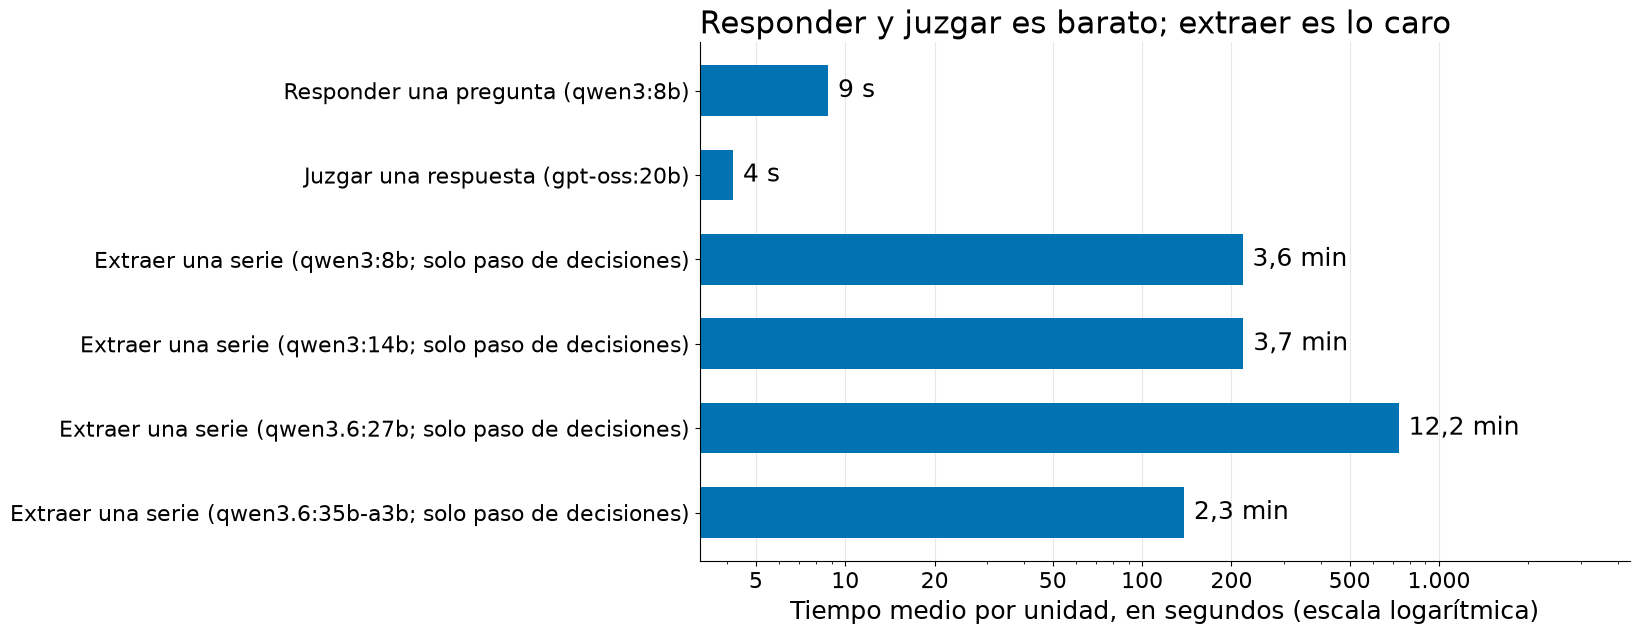

In [45]:
def seconds_text(value):
    return f"{es(value / 60, 1)} min" if value >= 120 else f"{es(value, 0)} s"


labels, values = {}, []
labels["Responder una pregunta (qwen3:8b)"] = answer_c1.mean_seconds
labels["Juzgar una respuesta (gpt-oss:20b)"] = judge_c1.mean_seconds
for m in MODEL_ORDER:
    labels[f"Extraer una serie ({m}; solo paso de decisiones)"] = float(ext[m])
with video_style():
    fig = plot_hbars(
        labels,
        annotations=[seconds_text(v) for v in labels.values()],
        xlabel="Tiempo medio por unidad, en segundos (escala logarítmica)",
        title="Responder y juzgar es barato; extraer es lo caro",
        log_x=True,
    )
    EXPORTED.append(save_figure(fig, FIGURES_DIR / "modelos-costo-latencia-por-rol.png"))
    display(fig)
    plt.close(fig)

---

# 9. Dificultades y aprendizajes

**Qué se hace y por qué.** El curso valora los intentos y los obstáculos. Los errores se dejan
escritos: el razonamiento es parte del aporte. Cada fila dice qué pasó, qué se hizo y en qué
estado queda.

In [46]:
n_inline = len(inline_marker_rows(RECORDS["C1"]))
weak = Q_CONFIRM[(Q_CONFIRM["model"] == BASELINE) & (Q_CONFIRM["series"] == "TS3009")].iloc[0]
weak_s = Q_SCREEN[(Q_SCREEN["model"] == BASELINE) & (Q_SCREEN["series"] == "TS3009")].iloc[0]
DIFFICULTIES = pd.DataFrame(
    [
        (
            "El recorte de contexto de OpenKOS invalidó una medición propia",
            f"El primer ajuste de C1 contó la evidencia sobre fragmentos completos y eligió "
            f"{FIRST.max_chars} / {FIRST.overlap_turns} / {FIRST.k} (recall "
            f"{es(FIRST.mean_recall, 3)}); al modelo le llegaba "
            f"un recall de {es(FIRST.mean_delivered_recall, 3)}. Se repitió contando el texto "
            "entregado y el ganador pasó a "
            f"{FINAL.max_chars} / {FINAL.overlap_turns} / {FINAL.k}",
            "Corregido y documentado como enmienda del ADR 0007, sin borrar el registro original",
        ),
        (
            "La marca de atribución `USED:` se pierde a veces",
            f"En {n_inline} de {len(RECORDS['C1'])} respuestas de C1 el modelo escribió `USED:` "
            "al final de la frase y OpenKOS "
            "solo lo reconoce al inicio de línea; se citaron todos los fragmentos y la "
            "*precision* de la citación bajó. "
            "Afecta a la citación, no a la corrección",
            "Pendiente: portar la corrección de OpenKOS a C1 cuando se publique y repetir la "
            "corrida de humo (#87)",
        ),
        (
            "La regla de citación tuvo que revisarse",
            "La primera versión exigía que todas las citas respaldaran la respuesta y rechazaba 8 "
            "de 13 respuestas, 7 de ellas "
            "correctas (cifras del ADR 0009). Se cambió a «al menos una» y la *precision* se "
            "informa aparte",
            "Resuelto (ADR 0009). Abierto: si el tamaño distinto de las citas de C1 y C2 sesga la "
            "comparación (#97)",
        ),
        (
            "La versión de OpenKOS no está fijada",
            "Las corridas de extracción usaron la 0.5.5; el *screen* usó el arnés de la 0.6.0; la "
            "rama principal ya cambia el "
            "modelo de la verificación de suficiencia (sección 5.6). `pyproject.toml` pide "
            "`openkos>=0.5.5` (un piso, no una versión)",
            "Pendiente (#94): fijar versión exacta y enmendar el ADR 0006 antes de cualquier "
            "corrida de evaluación",
        ),
        (
            "Cruce de idiomas",
            "Toda la extracción sale en inglés y la referencia está en español; ni la oración "
            "inglesa de origen alcanza "
            "una similitud alta contra su propia referencia en español. La cobertura colapsa con "
            "τ alto por el idioma, "
            "no por los modelos (notebook 15)",
            "Mitigado: la referencia se traduce al inglés para comparar (la traducción nunca es "
            "una etiqueta) y τ se calibra después de traducir",
        ),
        (
            "El control nulo del umbral τ tiene un defecto",
            "Al cruzar dos equipos con el mismo encargo de diseño, parte del «azar» es la misma "
            "decisión de verdad; la regla "
            "prerregistrada daba τ = 0,80 y casi no dejaba cobertura real",
            "Desvío declarado: τ principal 0,70 con 0,75 y 0,80 de sensibilidad (ADR 0012). "
            "Pendiente: concordancia del juez con una persona sobre 50 pares",
        ),
        (
            "El modelo base es menos fiable de lo que el *screen* mostraba",
            f"Con 5 corridas `{BASELINE}` no falló ninguna reunión en TS3009 "
            f"({int(weak_s.failed_meeting_runs)} de "
            f"{int(weak_s.meeting_runs)}); con 15 corridas nuevas fallaron "
            f"{int(weak.failed_meeting_runs)} de "
            f"{int(weak.meeting_runs)} por tope de generación. Cinco corridas subestiman la "
            "variación",
            "Aprendizaje: la confirmatoria con corridas nuevas no es un trámite. Alimenta la "
            "decisión del extractor (#143)",
        ),
        (
            "C2 pierde en E1 frente a C1",
            f"{SUMMARY['C2']['E1'].correct} de {SUMMARY['C2']['E1'].n} frente a "
            f"{SUMMARY['C1']['E1'].correct} de {SUMMARY['C1']['E1'].n}; "
            "las abstenciones de ambas condiciones las decidió la verificación de suficiencia",
            f"OE4 etiquetado por jss: recuperación {OE4_STAGES['recuperacion']}, extracción "
            f"{OE4_STAGES['extraccion']}, síntesis {OE4_STAGES['sintesis']} (de {n_oe4_total} "
            "fallas; una serie, una persona). Pendiente: decisión sobre fuentes en bruto en C2 "
            "(#146)",
        ),
        (
            "El cargador de la referencia no leía TS3009",
            "Las dos filas compuestas de TS3009 traen vacíos la reunión, la oración y la cita de "
            "sus hijas, y el cargador buscaba "
            "la transcripción de una reunión vacía",
            "Corregido con prueba: una hija vacía hereda los campos de su fila compuesta "
            "(notebook 15)",
        ),
        (
            "El juez es indulgente con una respuesta genérica y estricto con una parcial",
            "Marcó correcta una respuesta sin contexto que no afirma lo que dice la referencia "
            "(sección 7.4) y marcó incorrecta una respuesta correcta en lo sustancial, "
            "por faltarle elementos (`q023`, sección 7.5); su calibración "
            "(42 ítems, una serie) pudo quedar algo inflada porque el identificador delataba cómo "
            "se generó cada respuesta",
            "Declarado. Mitigación prevista: verificación humana del 20 % de las respuestas del "
            "experimento",
        ),
    ],
    columns=["dificultad", "qué pasó", "qué se hizo / estado"],
)
DIFFICULTIES.index = range(1, len(DIFFICULTIES) + 1)
DIFFICULTIES

,dificultad,qué pasó,qué se hizo / estado
1,El recorte de contexto de OpenKOS invalidó una medición propia,"El primer ajuste de C1 contó la evidencia sobre fragmentos completos y eligió 1600 / 0 / 8 (recall 0,642); al modelo...","Corregido y documentado como enmienda del ADR 0007, sin borrar el registro original"
2,La marca de atribución `USED:` se pierde a veces,En 2 de 21 respuestas de C1 el modelo escribió `USED:` al final de la frase y OpenKOS solo lo reconoce al inicio de ...,Pendiente: portar la corrección de OpenKOS a C1 cuando se publique y repetir la corrida de humo (#87)
3,La regla de citación tuvo que revisarse,"La primera versión exigía que todas las citas respaldaran la respuesta y rechazaba 8 de 13 respuestas, 7 de ellas co...",Resuelto (ADR 0009). Abierto: si el tamaño distinto de las citas de C1 y C2 sesga la comparación (#97)
4,La versión de OpenKOS no está fijada,Las corridas de extracción usaron la 0.5.5; el *screen* usó el arnés de la 0.6.0; la rama principal ya cambia el mod...,Pendiente (#94): fijar versión exacta y enmendar el ADR 0006 antes de cualquier corrida de evaluación
5,Cruce de idiomas,Toda la extracción sale en inglés y la referencia está en español; ni la oración inglesa de origen alcanza una simil...,Mitigado: la referencia se traduce al inglés para comparar (la traducción nunca es una etiqueta) y τ se calibra desp...
6,El control nulo del umbral τ tiene un defecto,"Al cruzar dos equipos con el mismo encargo de diseño, parte del «azar» es la misma decisión de verdad; la regla prer...","Desvío declarado: τ principal 0,70 con 0,75 y 0,80 de sensibilidad (ADR 0012). Pendiente: concordancia del juez con ..."
7,El modelo base es menos fiable de lo que el *screen* mostraba,Con 5 corridas `qwen3:8b` no falló ninguna reunión en TS3009 (0 de 20); con 15 corridas nuevas fallaron 6 de 60 por ...,Aprendizaje: la confirmatoria con corridas nuevas no es un trámite. Alimenta la decisión del extractor (#143)
8,C2 pierde en E1 frente a C1,5 de 14 frente a 10 de 14; las abstenciones de ambas condiciones las decidió la verificación de suficiencia,"OE4 etiquetado por jss: recuperación 4, extracción 3, síntesis 2 (de 9 fallas; una serie, una persona). Pendiente: d..."
9,El cargador de la referencia no leía TS3009,"Las dos filas compuestas de TS3009 traen vacíos la reunión, la oración y la cita de sus hijas, y el cargador buscaba...",Corregido con prueba: una hija vacía hereda los campos de su fila compuesta (notebook 15)
10,El juez es indulgente con una respuesta genérica y estricto con una parcial,Marcó correcta una respuesta sin contexto que no afirma lo que dice la referencia (sección 7.4) y marcó incorrecta u...,Declarado. Mitigación prevista: verificación humana del 20 % de las respuestas del experimento


**Lectura.** Dos aprendizajes atraviesan la lista. **Primero, medir lo que de verdad llega al
modelo**: el recorte de contexto de OpenKOS invalidó una medición propia, y la lección se
aplicó después (el mismo cuidado con τ, con el idioma y con las abstenciones). **Segundo,
desconfiar de las muestras pequeñas**: cinco corridas ocultaron la fragilidad del modelo base,
una serie de desarrollo no basta para elegir un extractor, y 21 preguntas dejan ver una
dirección y no una magnitud. Por eso casi cada fila termina en «declarado» o «pendiente» en
lugar de «resuelto».

---

# 10. Decisiones pendientes y congelamiento

**Qué se hace y por qué.** El equivalente a «usar el conjunto de prueba una sola vez» es
**congelar todo y luego correr**. Esta sección lista lo que falta decidir y lo que debe quedar
registrado antes de abrir una sola serie de evaluación. No decide nada: ordena las decisiones.

## 10.1 Decisiones abiertas

In [47]:
bank_rows = f"{BANK_WRITTEN} de {BANK_ROWS} filas escritas"
PENDING = pd.DataFrame(
    [
        (
            "Modelo extractor de C2 y alcance de la regla del «mismo modelo» (#143)",
            f"`{WINNER_SCREEN}` gana en F1 pero tarda {es(ratio27['TS3009'], 1)} a "
            f"{es(ratio27['ES2015'], 1)} veces más; "
            "`qwen3:8b` es el más rápido pero falló reuniones en la confirmatoria; "
            "`qwen3.6:35b-a3b` es más rápido que el 27b "
            "pero no pasa la regla de OpenKOS con 15 corridas. ¿La regla de la propuesta (§5.3) "
            "obliga al extractor a ser "
            "el mismo modelo que responde, o solo al que responde?",
            "Cambia el costo del Experimento A y el sentido de comparar C2 con C1 y C3",
        ),
        (
            "Fijar la versión de OpenKOS (#94)",
            "Hoy hay un piso (`>=0.5.5`), no una versión; la 0.6.0 ya existe y la rama principal "
            "cambia la verificación de suficiencia",
            "Ninguna evaluación se corre sin versión fijada; hay que enmendar el ADR 0006",
        ),
        (
            "Verificación de suficiencia de C2 y C3 (sección 5.6)",
            "Versión sin esa verificación, o `models: {sufficiency: qwen3:8b}` en el espacio de "
            "trabajo",
            "Sin esto, C1 y C2 abstendrían con modelos distintos",
        ),
        (
            "Fuentes en bruto en C2 (#146)",
            "C2 recupera la transcripción en bruto (`sources/`), que no es resultado de la "
            "extracción; hay que decidir si cuenta como parte de C2. Ya hay evidencia de OE4: "
            f"recuperación {OE4_STAGES['recuperacion']}, extracción {OE4_STAGES['extraccion']}, "
            f"síntesis {OE4_STAGES['sintesis']} (desarrollo, una serie)",
            "Cambia qué mide la comparación en E1 (notebook 16)",
        ),
        (
            "Concordancia del juez de τ con una persona",
            "50 pares de la muestra juzgada; sin anotador asignado (ADR 0012)",
            "Si es baja, el ADR 0012 se reemplaza con otro",
        ),
    ],
    columns=["decisión", "estado y opciones", "qué cambia"],
)
PENDING.index = range(1, len(PENDING) + 1)
PENDING

,decisión,estado y opciones,qué cambia
1,Modelo extractor de C2 y alcance de la regla del «mismo modelo» (#143),"`qwen3.6:27b` gana en F1 pero tarda 1,8 a 3,6 veces más; `qwen3:8b` es el más rápido pero falló reuniones en la conf...",Cambia el costo del Experimento A y el sentido de comparar C2 con C1 y C3
2,Fijar la versión de OpenKOS (#94),"Hoy hay un piso (`>=0.5.5`), no una versión; la 0.6.0 ya existe y la rama principal cambia la verificación de sufici...",Ninguna evaluación se corre sin versión fijada; hay que enmendar el ADR 0006
3,Verificación de suficiencia de C2 y C3 (sección 5.6),"Versión sin esa verificación, o `models: {sufficiency: qwen3:8b}` en el espacio de trabajo","Sin esto, C1 y C2 abstendrían con modelos distintos"
4,Fuentes en bruto en C2 (#146),"C2 recupera la transcripción en bruto (`sources/`), que no es resultado de la extracción; hay que decidir si cuenta ...",Cambia qué mide la comparación en E1 (notebook 16)
5,Concordancia del juez de τ con una persona,50 pares de la muestra juzgada; sin anotador asignado (ADR 0012),"Si es baja, el ADR 0012 se reemplaza con otro"


## 10.2 Lo que debe estar listo y congelado antes de la corrida de evaluación

In [48]:
ADJ_EVAL = [s for s in ADJUDICATED if s in CORPUS["evaluation_series"]]
READY = pd.DataFrame(
    [
        (
            "Referencia adjudicada de las 11 series de evaluación (OE1)",
            f"{len(ADJUDICATED)} de {len(CORPUS['series'])} series adjudicadas ({len(ADJ_EVAL)} "
            f"de {len(CORPUS['evaluation_series'])} de evaluación)",
            "Pendiente",
        ),
        (
            "Banco de preguntas (≥ 25 por estrato) validado",
            bank_rows,
            "Pendiente",
        ),
        ("C3 ejecutable", "depende de la referencia; hoy lanza «sin implementar»", "Pendiente"),
        (
            "Modelos y huellas (generador, *embeddings*, extractor, juez)",
            "juez, generador y *embeddings* definidos; extractor por decidir",
            "Parcial",
        ),
        ("Versión de OpenKOS", "sin fijar (#94)", "Pendiente"),
        (
            "Parámetros de C1",
            f"{C1P['max_chars']} / {C1P['overlap_turns']} / {C1P['k']}, en "
            "`config/experiments.toml`; una prueba verifica que coinciden con el ganador guardado",
            "Congelado",
        ),
        (
            "Umbral τ",
            "0,70 principal; 0,75 y 0,80 de sensibilidad (ADR 0012)",
            "Congelado, con concordancia del juez pendiente",
        ),
        (
            "*Prompts* de respuesta",
            "copia byte a byte con huella SHA-256 verificada por prueba (ADR 0006)",
            "Congelado",
        ),
        ("Criterio de éxito", "D16/D17, escrito antes de ejecutar (ADR 0010)", "Congelado"),
        (
            "Verificación humana del 20 % del juez",
            f"{pct(EVAL['human_validation_fraction'], 0)} de las respuestas, kappa ≥ "
            f"{es(JC['min_kappa_correct'], 2)}",
            "Pendiente (sobre el Experimento B)",
        ),
        (
            "Registro del congelamiento",
            "un ADR que liste modelos, huellas, versión de OpenKOS y *commit* del código antes de "
            "la primera corrida",
            "Pendiente",
        ),
    ],
    columns=["requisito", "estado hoy", "situación"],
)
READY.index = range(1, len(READY) + 1)
READY

,requisito,estado hoy,situación
1,Referencia adjudicada de las 11 series de evaluación (OE1),5 de 14 series adjudicadas (3 de 11 de evaluación),Pendiente
2,Banco de preguntas (≥ 25 por estrato) validado,0 de 115 filas escritas,Pendiente
3,C3 ejecutable,depende de la referencia; hoy lanza «sin implementar»,Pendiente
4,"Modelos y huellas (generador, *embeddings*, extractor, juez)","juez, generador y *embeddings* definidos; extractor por decidir",Parcial
5,Versión de OpenKOS,sin fijar (#94),Pendiente
6,Parámetros de C1,"1200 / 1 / 5, en `config/experiments.toml`; una prueba verifica que coinciden con el ganador guardado",Congelado
7,Umbral τ,"0,70 principal; 0,75 y 0,80 de sensibilidad (ADR 0012)","Congelado, con concordancia del juez pendiente"
8,*Prompts* de respuesta,copia byte a byte con huella SHA-256 verificada por prueba (ADR 0006),Congelado
9,Criterio de éxito,"D16/D17, escrito antes de ejecutar (ADR 0010)",Congelado
10,Verificación humana del 20 % del juez,"20 % de las respuestas, kappa ≥ 0,70",Pendiente (sobre el Experimento B)


**Lectura.** Lo congelado es lo que se pudo ajustar en desarrollo (C1, τ, los *prompts*, el
criterio de éxito). Lo pendiente depende de decisiones del equipo (extractor, versión) o de
trabajo humano en curso (anotación, banco de preguntas). La regla de oro, la misma del
ADR 0005: **nada se ajusta ya con las series de evaluación**; si algo debe cambiar, se cambia
con un ADR nuevo y sobre desarrollo, antes de la primera corrida.

---

# 11. Limitaciones

**Qué se hace y por qué.** El análisis crítico de la línea base y del *pipeline* exige decir
qué no se puede concluir. Se agrupan por origen.

**De los datos**

- Todo el desempeño mostrado sale de **una serie de desarrollo** (ES2015) con 21 preguntas, una
  corrida por condición (tres en C0) y un solo caso de evolución (E3). Indica una dirección, no
  una magnitud, y no es generalizable.
- El corpus es un único dominio (diseño de un control remoto) con habla actuada; 14 series
  elegidas por criterios, no al azar.
- La referencia está en español y se compara con una traducción automática al inglés; la
  traducción no es una etiqueta, pero introduce ruido propio. El banco y la calibración están en
  inglés, así que el desempeño con preguntas en español no se midió.
- Todavía no se conocen las **relaciones reales** entre decisiones: la viabilidad de E3 es
  plausible, no demostrada (documento 08).

**De los modelos y de la medición**

- Los parámetros de C1 se ajustaron en una sola serie con 17 preguntas, y la diferencia entre
  las dos mejores configuraciones está dentro del ruido.
- El *recall* de evidencia es un piso: AMI suele enlazar un solo acto de diálogo por respuesta.
- La temperatura, la semilla, `top_p` y la ventana se fijaron por diseño y **no se exploró** su
  sensibilidad; tampoco se compararon otros generadores de respuestas.
- La elección del extractor se apoya en dos series de desarrollo y un puntaje (τ = 0,60) que
  incluye parecido temático; la decisión final no está tomada.
- El juez se calibró con 42 ítems de una serie, generados por el mismo generador y con un
  identificador que delataba su origen. Su validación con personas sobre el experimento real
  sigue pendiente.
- El juez tiene dos sesgos vistos al etiquetar: es **indulgente con una respuesta genérica**
  que no se compromete (C0, `q008`) y **estricto con una respuesta parcial** correcta en lo
  sustancial (C2, `q023`, un falso negativo; también `q011`). Infla el piso de C0 y puede
  subestimar a C2, y es una razón más para la verificación humana del 20 %.
- La citación se mide con una regla determinista aparte; el juez no evalúa las citas, y queda
  abierto si el tamaño distinto de las citas de C1 y C2 sesga la comparación (#97).

**De la comparación**

- La verificación de suficiencia puede romper la igualdad entre C1 y C2 si no se controla la
  versión de OpenKOS (sección 5.6).
- Las instrucciones de OpenKOS hablan de *concepts* y de *compiled bundle*, lo que no
  describe fragmentos de transcripción; se copiaron igual a C1 y se declara.
- C1 no puede, por diseño, saber que dos fragmentos de reuniones distintas tratan de la misma
  decisión: esa es justamente la debilidad que C2 y C3 intentan superar.
- C3 es una **referencia**, no un «techo teórico»: una anotación humana con fiabilidad medida no
  es un límite superior demostrable.
- Dos umbrales de troceo de OpenKOS se midieron con una serie de evaluación (#145): fuga
  declarada, de bajo riesgo, pero declarada.
- El formato OKF de OpenKOS es un borrador sin versión estable: si cambia, las bases se
  recompilan.

---

# 12. Resumen para el avance y el video

**Qué se hace y por qué.** Los mensajes clave, en lenguaje llano, cada uno con su cifra y la
sección donde se justifica. Las cifras se calculan en este mismo notebook y se pueden llevar
tal cual al documento 09 y al guion. Todas son de desarrollo salvo los conteos del reparto.

In [49]:
b27 = RULE_CONFIRM.set_index("series")["d_f1"]
kappa_sel = next(c.kappa for c in JUDGE.candidates if c.model == JUDGE.selected)
jac_lo, jac_hi = different["jaccard"].min(), different["jaccard"].max()
c0, c1_, c2_ = (TOTALS[k][0] / TOTALS[k][1] for k in ("C0", "C1", "C2"))
md(
    f"""
1. **Qué se modela y por qué no hay entrenamiento** (secciones 0 y 4). La tesis compara
tres *pipelines* que solo se diferencian en
   la representación que consultan: buscar fragmentos (C1, la línea base), una base de decisiones
   construida
   por la máquina (C2) y la misma base construida por personas (C3). Todos usan modelos de lenguaje
   ya
   entrenados, en local, con el mismo generador (`{SB["generative_model"]}`), los
   mismos *embeddings* (`{SB["embedding_model"]}`)
   y el mismo presupuesto de contexto.
2. **Qué es «funcionar bien»** (sección 1). Un solo criterio decide el éxito: la corrección de la
respuesta en las preguntas
   de evolución, de C2 frente a C1, por diferencia pareada con intervalo bootstrap. Con
   {QB["min_questions"]} preguntas y una mejora
   verdadera de +0,15 ese criterio la detecta en {p25["criterio pareado (vigente)"]} de los casos
   simulados.
3. **Los datos imponen límites** (sección 2). Ninguna serie cabe en la ventana del modelo
({es(CON.series_window_ratio_min, 1)} a
   {es(CON.series_window_ratio_max, 1)} veces su tamaño), las decisiones son raras
   ({es(CON.decisions_per_1000_turns, 1)} por cada 1.000 turnos)
   y {CON.n_without_evidence} de {CON.n_decisions} no tienen evidencia.
4. **El reparto** (sección 3). Desarrollo, para elegir: {int(dev["series"])} de
{int(tot["series"])} series, {es(dev["decisions"])} de
   {es(tot["decisions"])} frases de decisión ({es(dev["pct_decisions"], 1)} %). Evaluación, para
   reportar: {int(ev["series"])} series,
   {es(ev["decisions"])} frases ({es(ev["pct_decisions"], 1)} %), sin tocar hasta congelar todo.
5. **Dos modelos se eligieron comparando candidatos** (sección 5). El juez, `{JUDGE.selected}`,
cumplió todos los umbrales fijados antes
   de correr (kappa {es(kappa_sel, 3)}) y fue el más rápido de los que cumplían. Para el extractor,
   `{WINNER_SCREEN}` gana en F1
   (+{es(b27["ES2015"], 2)} y +{es(b27["TS3009"], 2)} sobre `{BASELINE}` en las dos series) pero
   tarda {es(ratio27["TS3009"], 1)} a
   {es(ratio27["ES2015"], 1)} veces más; la decisión está abierta (#143).
6. **Cómo se buscaron los parámetros** (sección 6). *Grid search* de {n_grid} configuraciones para
C1 (ganadora {FINAL.max_chars} / {FINAL.overlap_turns} / {FINAL.k}),
   con una corrección propia: el primer ajuste sobrestimaba la evidencia porque OpenKOS recorta el
   contexto. La ablación muestra que
   el canal híbrido entrega {es(abl["hybrid"].mean_delivered_recall, 3)} de la evidencia frente a
   {es(abl["dense"].mean_delivered_recall, 3)}
   y {es(abl["bm25"].mean_delivered_recall, 3)} de los canales por separado. El umbral τ es 0,70,
   con un desvío declarado.
7. **La línea base y los primeros resultados** (sección 7; desarrollo, 21 preguntas, no son
resultados de la tesis). Sin contexto el modelo acierta
   {pct(c0)}; con la recuperación de C1, {pct(c1_)}; con la base de C2, {pct(c2_)}. Recuperar texto
   aporta mucho, no hay indicio de que el modelo
   conozca AMI de memoria, y C2 pierde frente a C1 en hechos puntuales. Las nueve fallas E1 de C2
   se reparten, según las etiquetas de jss y la regla, en recuperación {OE4_STAGES["recuperacion"]},
   extracción {OE4_STAGES["extraccion"]} y síntesis {OE4_STAGES["sintesis"]}: una dirección de una
   sola serie, no un resultado. El juez es indulgente con lo genérico y estricto con lo parcial.
8. **Variabilidad y reproducibilidad** (sección 8). Con la misma semilla la extracción se repite
idéntica; con semillas distintas el
   índice de Jaccard entre corridas va de {es(jac_lo, 2)} a {es(jac_hi, 2)}, por eso cada
   configuración se corre {SB["runs_per_config"]} veces.
   Cada corrida guarda la huella exacta de sus modelos.
9. **Costo** (sección 8.3). Responder una pregunta tarda unos {es(answer_c1.mean_seconds, 0)} s y
juzgarla unos {es(judge_c1.mean_seconds, 0)} s; extraer una
   serie tarda de {es(ext.min(), 0)} a {es(ext.max(), 0)} s según el modelo: el costo está en la
   extracción.
10. **Dificultades y lo que falta** (secciones 9 a 11). El recorte de contexto de OpenKOS invalidó
una medición propia y se corrigió; la
    verificación de suficiencia puede romper la igualdad entre condiciones; la versión de OpenKOS,
    el extractor, el banco de preguntas y C3
    siguen pendientes. Todo lo mostrado sale de una serie de desarrollo.
"""
)


1. **Qué se modela y por qué no hay entrenamiento** (secciones 0 y 4). La tesis compara
tres *pipelines* que solo se diferencian en
   la representación que consultan: buscar fragmentos (C1, la línea base), una base de decisiones
   construida
   por la máquina (C2) y la misma base construida por personas (C3). Todos usan modelos de lenguaje
   ya
   entrenados, en local, con el mismo generador (`qwen3:8b`), los
   mismos *embeddings* (`bge-m3`)
   y el mismo presupuesto de contexto.
2. **Qué es «funcionar bien»** (sección 1). Un solo criterio decide el éxito: la corrección de la
respuesta en las preguntas
   de evolución, de C2 frente a C1, por diferencia pareada con intervalo bootstrap. Con
   25 preguntas y una mejora
   verdadera de +0,15 ese criterio la detecta en 57,5 % de los casos
   simulados.
3. **Los datos imponen límites** (sección 2). Ninguna serie cabe en la ventana del modelo
(1,6 a
   2,8 veces su tamaño), las decisiones son raras
   (13,3 por cada 1.000 turnos)
   y 26 de 343 no tienen evidencia.
4. **El reparto** (sección 3). Desarrollo, para elegir: 3 de
14 series, 77 de
   343 frases de decisión (22,4 %). Evaluación, para
   reportar: 11 series,
   266 frases (77,6 %), sin tocar hasta congelar todo.
5. **Dos modelos se eligieron comparando candidatos** (sección 5). El juez, `gpt-oss:20b`,
cumplió todos los umbrales fijados antes
   de correr (kappa 0,951) y fue el más rápido de los que cumplían. Para el extractor,
   `qwen3.6:27b` gana en F1
   (+0,18 y +0,17 sobre `qwen3:8b` en las dos series) pero
   tarda 1,8 a
   3,6 veces más; la decisión está abierta (#143).
6. **Cómo se buscaron los parámetros** (sección 6). *Grid search* de 32 configuraciones para
C1 (ganadora 1200 / 1 / 5),
   con una corrección propia: el primer ajuste sobrestimaba la evidencia porque OpenKOS recorta el
   contexto. La ablación muestra que
   el canal híbrido entrega 0,569 de la evidencia frente a
   0,417
   y 0,373 de los canales por separado. El umbral τ es 0,70,
   con un desvío declarado.
7. **La línea base y los primeros resultados** (sección 7; desarrollo, 21 preguntas, no son
resultados de la tesis). Sin contexto el modelo acierta
   22,2 %; con la recuperación de C1, 76,2 %; con la base de C2, 47,6 %. Recuperar texto
   aporta mucho, no hay indicio de que el modelo
   conozca AMI de memoria, y C2 pierde frente a C1 en hechos puntuales. Las nueve fallas E1 de C2
   se reparten, según las etiquetas de jss y la regla, en recuperación 4,
   extracción 3 y síntesis 2: una dirección de una
   sola serie, no un resultado. El juez es indulgente con lo genérico y estricto con lo parcial.
8. **Variabilidad y reproducibilidad** (sección 8). Con la misma semilla la extracción se repite
idéntica; con semillas distintas el
   índice de Jaccard entre corridas va de 0,70 a 0,82, por eso cada
   configuración se corre 3 veces.
   Cada corrida guarda la huella exacta de sus modelos.
9. **Costo** (sección 8.3). Responder una pregunta tarda unos 9 s y
juzgarla unos 4 s; extraer una
   serie tarda de 138 a 732 s según el modelo: el costo está en la
   extracción.
10. **Dificultades y lo que falta** (secciones 9 a 11). El recorte de contexto de OpenKOS invalidó
una medición propia y se corrigió; la
    verificación de suficiencia puede romper la igualdad entre condiciones; la versión de OpenKOS,
    el extractor, el banco de preguntas y C3
    siguen pendientes. Todo lo mostrado sale de una serie de desarrollo.
